# Caso E — OSIPTEL: Reclamos de usuarios en telecomunicaciones
### PC2 — Proyecto ejecutado: enriquecimiento, modelado, hallazgos y recomendaciones

**Grupo 5**

---

## 1. Problema de negocio

OSIPTEL recibe un volumen muy alto de reclamos de usuarios de servicios de
telecomunicaciones, pero la información se publica de forma agregada y descriptiva:
se sabe *cuántos* reclamos hay, no *qué tan riesgosa* es realmente cada operadora
ni dónde conviene concentrar la fiscalización.

El área de supervisión necesita priorizar con criterio: no todas las empresas con
muchos reclamos son igual de problemáticas (una operadora grande naturalmente
recibe más reclamos que una pequeña), y no todos los reclamos escalan a una
infracción formal. Hoy esa priorización se hace de manera reactiva.

**Problema:** no existe un criterio cuantitativo que combine volumen de reclamos,
concentración por servicio/materia y exposición sancionadora real para priorizar
la supervisión de operadoras.

## 2. Pregunta huérfana

> *¿Las operadoras que acumulan más reclamos ante OSIPTEL son las mismas que
> efectivamente terminan sancionadas por INDECOPI, o el volumen de reclamos es un
> mal predictor del riesgo regulatorio real?*

Es huérfana porque **ningún dataset la responde por sí solo**: OSIPTEL tiene los
reclamos pero no las sanciones; INDECOPI tiene las sanciones pero no los reclamos.
Solo el cruce de ambas fuentes permite contestarla.

## 3. Preguntas analíticas

1. ¿Qué operadoras concentran el mayor volumen de reclamos presentados (2023–2025)?
2. ¿Qué servicios y materias reclamables concentran el problema?
3. ¿Cómo se distribuyen geográficamente los reclamos por departamento?
4. ¿Cuál es la evolución mensual del volumen de reclamos por operadora?
5. ¿Existe correlación entre el volumen de reclamos (OSIPTEL) y las sanciones y
   montos en UIT impuestos (INDECOPI)?
6. ¿Qué proporción de las operadoras con reclamos llega a tener sanción formal?

## 4. Datasets

| # | Fuente | Contenido | Periodo | Rol |
|---|--------|-----------|---------|-----|
| 1 | OSIPTEL — Reclamos presentados | Reclamos por empresa, mes, servicio, materia, departamento | 2023–2025 | **Base** |
| 2 | INDECOPI — Ranking de proveedores sancionados (sector Telecomunicaciones, todas las sedes) | Total de sanciones y monto en UIT por razón social | 12/09/2022 – 11/09/2026 | **Enriquecimiento** |
| 3 | Encuesta propia (Grupo 5) | Experiencia y fricción del usuario al reclamar | 2026 | **Enriquecimiento** |

## 5. Estrategia de enriquecimiento

El dataset base de OSIPTEL se enriquece con la fuente pública de INDECOPI mediante
un **cruce por razón social normalizada**. Como los nombres no coinciden
literalmente entre ambas fuentes (tildes, puntuación, sufijos societarios,
mayúsculas), se aplica una función de normalización antes del `merge`.

El resultado es un dataset consolidado que incorpora dos variables nuevas a nivel
de operadora: `total_sanciones` y `monto_uit`. La encuesta propia se cruza después,
también por operadora, para contrastar la experiencia declarada por los usuarios
con el riesgo observado en los datos.

**Limitación del cruce: los periodos no son idénticos.** Los reclamos de OSIPTEL
cubren enero 2023 – diciembre 2025 (36 meses), mientras que el ranking de INDECOPI
acumula las sanciones del 12/09/2022 al 11/09/2026 (48 meses) y no publica el
detalle por fecha, por lo que no es posible recortarlo al mismo periodo. En
consecuencia, los indicadores de sanciones por reclamo sirven para **comparar
operadoras entre sí** (todas se miden con la misma ventana), pero su valor absoluto
está algo sobreestimado y no debe leerse como una tasa exacta.

# Configuración y carga de datos

In [1]:
# ============================================================
# Montar Google Drive (solo en Colab)
# ============================================================
try:
    from google.colab import drive
    drive.mount('/content/drive')
    EN_COLAB = True
except ImportError:
    EN_COLAB = False
print("Ejecutando en Colab:", EN_COLAB)

Mounted at /content/drive
Ejecutando en Colab: True


In [2]:
# ============================================================
# Configuración del entorno
# ============================================================
import os, re, logging, warnings, unicodedata

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

mpl.rcParams.update(mpl.rcParamsDefault)
logging.getLogger('matplotlib.font_manager').setLevel(logging.ERROR)
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=UserWarning, module='openpyxl')

sns.set_theme(style="whitegrid")
plt.rcParams['font.family'] = 'DejaVu Sans'
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 160)

COL_REC = 'N° de Reclamos Presentados'   # variable de volumen de OSIPTEL

# ---------- Función de normalización de razón social (llave de cruce) ----------
# Los puntos se quitan ANTES, para que "S.A.A." se convierta en "SAA" y el patrón lo reconozca.
SUFIJOS = (r"\b(SAA|SAC|SA|SRL|SCRL|EIRL|SOCIEDAD ANONIMA( ABIERTA| CERRADA)?|"
           r"SUCURSAL|DEL PERU|PERU|PERUANA|LTDA|LTD|INC|CORP|COMPANY|GROUP)\b")

def normalizar_empresa(nombre):
    '''Normaliza una razón social para cruzar fuentes distintas:
    mayúsculas, sin tildes, sin puntuación y sin sufijos societarios.'''
    if pd.isna(nombre):
        return np.nan
    txt = str(nombre).upper().strip()
    txt = ''.join(c for c in unicodedata.normalize('NFKD', txt) if not unicodedata.combining(c))
    txt = txt.replace('.', '')
    txt = re.sub(r'[^\w\s]', ' ', txt)
    for _ in range(3):                      # "PERU SAC" necesita 2 pasadas
        txt = re.sub(SUFIJOS, ' ', txt)
        txt = re.sub(r'\s+', ' ', txt).strip()
    return txt if txt else np.nan

def a_numero(serie):
    '''Convierte texto con separadores de miles a número.'''
    return pd.to_numeric(serie.astype(str).str.replace(r'[^\d,.\-]', '', regex=True)
                         .str.replace(',', '', regex=False), errors='coerce')

print("pandas:", pd.__version__, "| seaborn:", sns.__version__)

pandas: 2.2.3 | seaborn: 0.13.2


In [3]:
# ============================================================
# RUTAS  <-- todos los archivos en la misma carpeta de Drive
# ============================================================
BASE_DIR = '/content/drive/MyDrive/AD3010_CasoE' if EN_COLAB else '.'
PROC_DIR = f'{BASE_DIR}/data/processed'
os.makedirs(PROC_DIR, exist_ok=True)

path_osiptel  = f'{BASE_DIR}/10.1 RECLAMOS PRESENTADOS.xlsx'
path_indecopi = f'{BASE_DIR}/ranking_proveedor.xlsx'
path_encuesta = f'{BASE_DIR}/Encuestas.xlsx'

for p in [path_osiptel, path_indecopi, path_encuesta]:
    print(("OK    " if os.path.exists(p) else "FALTA "), p)

OK     /content/drive/MyDrive/AD3010_CasoE/10.1 RECLAMOS PRESENTADOS.xlsx
OK     /content/drive/MyDrive/AD3010_CasoE/ranking_proveedor.xlsx
OK     /content/drive/MyDrive/AD3010_CasoE/Encuestas.xlsx


In [4]:
# ============================================================
# Carga de datos crudos (una sola vez)
# ============================================================
df_raw      = pd.read_excel(path_osiptel, header=3)       # 3 filas de título institucional
indecopi_raw = pd.read_excel(path_indecopi, skiprows=2)    # 2 filas de título institucional
encuesta_raw = pd.read_excel(path_encuesta)

print("OSIPTEL crudo  :", df_raw.shape)
print("INDECOPI crudo :", indecopi_raw.shape)
print("Encuesta cruda :", encuesta_raw.shape)
print("\nColumnas OSIPTEL:", list(df_raw.columns))

OSIPTEL crudo  : (233892, 8)
INDECOPI crudo : (41, 5)
Encuesta cruda : (59, 11)

Columnas OSIPTEL: ['Unnamed: 0', 'Empresa operadora', 'Mes', 'Departamento', 'Servicio involucrado', 'Forma de Presentación', 'Materia reclamable', 'N° de Reclamos Presentados']


# Calidad del dato crudo (antes de limpiar)

In [5]:
# ============================================================
# EDA 0: Calidad de datos - OSIPTEL crudo (2016-2025)
# ============================================================
resumen_nulos = pd.DataFrame({'nulos': df_raw.isnull().sum(),
                              'pct': (df_raw.isnull().mean() * 100).round(2)}).sort_values('nulos', ascending=False)
display(resumen_nulos)
print("Registros duplicados exactos:", df_raw.duplicated().sum())
print("Rango temporal crudo:", df_raw['Mes'].min(), "->", df_raw['Mes'].max())
display(df_raw[[COL_REC]].describe())

,nulos,pct
Unnamed: 0,233892,100.0
Empresa operadora,0,0.0
Mes,0,0.0
Departamento,0,0.0
Servicio involucrado,0,0.0
Forma de Presentación,0,0.0
Materia reclamable,0,0.0
N° de Reclamos Presentados,0,0.0


Registros duplicados exactos: 10385
Rango temporal crudo: 2016-01-01 00:00:00 -> 2025-12-31 00:00:00


,N° de Reclamos Presentados
count,233892.000000
mean,84.557706
std,1108.273532
min,1.000000
25%,1.000000
50%,2.000000
75%,8.000000
max,71299.000000


#Limpieza y preparación

In [6]:
# ============================================================
# Limpieza 1: OSIPTEL - columnas, nulos y tipos
# ============================================================
df_presentados = df_raw.copy()

cols_unnamed = [c for c in df_presentados.columns if str(c).startswith('Unnamed')]
df_presentados = df_presentados.drop(columns=cols_unnamed)

df_presentados = df_presentados.replace(r'^\s*-+\s*$', np.nan, regex=True)
df_presentados = df_presentados.replace(r'^\s*$', np.nan, regex=True)

antes = len(df_presentados)
df_presentados = df_presentados.dropna(subset=['Empresa operadora'])
df_presentados[COL_REC] = pd.to_numeric(df_presentados[COL_REC], errors='coerce')

print("Columnas auxiliares eliminadas (100% nulas):", cols_unnamed)
print("Registros sin empresa eliminados:", antes - len(df_presentados))

Columnas auxiliares eliminadas (100% nulas): ['Unnamed: 0']
Registros sin empresa eliminados: 0


In [7]:
# ============================================================
# Limpieza 2: Fechas y filtro temporal oficial del caso (2023-2025)
# ============================================================
# OSIPTEL publica 2025 con fechas de FIN de mes (ej. 2025-01-31) y 2023-2024 con
# INICIO de mes. Sin normalizar, esos meses se pierden al construir la serie mensual.
df_presentados['Mes'] = pd.to_datetime(df_presentados['Mes'], errors='coerce')
fechas_invalidas  = df_presentados['Mes'].isna().sum()
fechas_fin_de_mes = (df_presentados['Mes'].dt.day != 1).sum()
df_presentados['Mes'] = df_presentados['Mes'].dt.to_period('M').dt.to_timestamp()

FECHA_INICIO, FECHA_FIN = '2023-01-01', '2025-12-01'
antes = len(df_presentados)
df_presentados = df_presentados[df_presentados['Mes'].between(FECHA_INICIO, FECHA_FIN)].copy()

print("BITÁCORA - FILTRO TEMPORAL")
print(f"  Fechas no legibles (NaT)            : {fechas_invalidas}")
print(f"  Fechas normalizadas a día 1 del mes : {fechas_fin_de_mes:,}")
print(f"  Registros fuera de 2023-2025        : {antes - len(df_presentados):,}")
print(f"  Registros dentro del rango          : {len(df_presentados):,}")
print(f"  Rango temporal                      : {df_presentados['Mes'].min():%Y-%m} -> {df_presentados['Mes'].max():%Y-%m}")
print(f"  Meses distintos                     : {df_presentados['Mes'].nunique()} (esperado: 36)")
assert df_presentados['Mes'].nunique() == 36, "Falta algún mes en la fuente: revisar antes de seguir"

BITÁCORA - FILTRO TEMPORAL
  Fechas no legibles (NaT)            : 0
  Fechas normalizadas a día 1 del mes : 5,877
  Registros fuera de 2023-2025        : 17,476
  Registros dentro del rango          : 216,416
  Rango temporal                      : 2023-01 -> 2025-12
  Meses distintos                     : 36 (esperado: 36)


In [8]:
# ============================================================
# Limpieza 3: Duplicados - diagnóstico y decisión documentada
# ============================================================
LLAVE = ['Empresa operadora', 'Mes', 'Departamento', 'Servicio involucrado',
         'Forma de Presentación', 'Materia reclamable']

dup_exactos = df_presentados.duplicated().sum()
dup_llave   = df_presentados.duplicated(subset=LLAVE).sum()
rec_dup     = df_presentados.loc[df_presentados.duplicated(), COL_REC].sum()

print(f"Filas duplicadas exactas            : {dup_exactos:,}")
print(f"Filas con la misma llave descriptiva: {dup_llave:,}")
print(f"Reclamos en filas duplicadas exactas: {rec_dup:,.0f} "
      f"({rec_dup / df_presentados[COL_REC].sum() * 100:.2f}% del total)")

# DECISIÓN: si hay más filas repetidas por llave que duplicados exactos, el archivo tiene
# un nivel de detalle que no viene como columna (p. ej. sub-categorías), y dos filas
# idénticas pueden ser registros distintos con el mismo conteo. En ese caso se CONSERVAN
# para no alterar los totales oficiales publicados por OSIPTEL.
ELIMINAR_DUPLICADOS = dup_llave <= dup_exactos
if ELIMINAR_DUPLICADOS:
    df_presentados = df_presentados.drop_duplicates()
    print("Decisión: se eliminan los duplicados exactos (la llave es única en la fuente).")
else:
    print("Decisión: se conservan (la fuente tiene más detalle que las columnas publicadas).")
print("Registros finales OSIPTEL:", f"{len(df_presentados):,}")

Filas duplicadas exactas            : 10,369
Filas con la misma llave descriptiva: 45,152
Reclamos en filas duplicadas exactas: 15,212 (0.36% del total)
Decisión: se conservan (la fuente tiene más detalle que las columnas publicadas).
Registros finales OSIPTEL: 216,416


In [9]:
# ============================================================
# Limpieza 4: INDECOPI - columnas, tipos y filas de título
# ============================================================
df_indecopi = indecopi_raw.copy()
df_indecopi = df_indecopi.iloc[:, :5]
df_indecopi.columns = ['posicion', 'razon_social', 'nombre_comercial', 'total_sanciones', 'monto_uit']
df_indecopi = df_indecopi.replace(r'^\s*-+\s*$', np.nan, regex=True)
for col in ['total_sanciones', 'monto_uit']:
    df_indecopi[col] = a_numero(df_indecopi[col])

antes = len(df_indecopi)
# La fila de encabezado del Excel ("Nro. / Razón social") no es un proveedor:
# se conservan solo las filas cuya posición en el ranking es un número.
df_indecopi = df_indecopi[pd.to_numeric(df_indecopi['posicion'], errors='coerce').notna()]
df_indecopi = df_indecopi.dropna(subset=['razon_social', 'total_sanciones']).reset_index(drop=True)
print(f"Filas de título/notas eliminadas: {antes - len(df_indecopi)}")
print(f"Proveedores sancionados en el ranking: {len(df_indecopi)}")
display(df_indecopi.head())

Filas de título/notas eliminadas: 9
Proveedores sancionados en el ranking: 32


,posicion,razon_social,nombre_comercial,total_sanciones,monto_uit
0,1,TELEFONICA DEL PERU SAA,TELEFONICA DEL PERU S.A.A,193.0,326.75
1,2,ENTEL PERU S.A.,NaN,192.0,81.93
2,3,FALABELLA.COM S.A.C.,FALABELLA.COM S.A.C.,75.0,3.49
3,4,AMERICA MOVIL PERU S.A.C.,AMERICA MOVIL PERU S.A.C.,59.0,61.84
4,5,LA TIENDA EN LINEA E.I.R.L.,NaN,13.0,15.68


# EDA posterior a la limpieza

In [10]:
# ============================================================
# EDA 1: Calidad y descriptivos - OSIPTEL limpio (2023-2025)
# ============================================================
print("Dimensiones:", df_presentados.shape)
display(df_presentados.isnull().sum().to_frame('nulos'))
display(df_presentados[[COL_REC]].describe())
print("Empresas únicas OSIPTEL :", df_presentados['Empresa operadora'].nunique())
print("Empresas únicas INDECOPI:", df_indecopi['razon_social'].nunique())

Dimensiones: (216416, 7)


,nulos
Empresa operadora,0
Mes,0
Departamento,0
Servicio involucrado,0
Forma de Presentación,0
Materia reclamable,0
N° de Reclamos Presentados,0


,N° de Reclamos Presentados
count,216416.000000
mean,19.384828
std,175.765498
min,1.000000
25%,1.000000
50%,2.000000
75%,6.000000
max,24289.000000


Empresas únicas OSIPTEL : 95
Empresas únicas INDECOPI: 32


In [11]:
# ============================================================
# EDA 2: Outliers en INDECOPI (regla IQR)
# ============================================================
for variable in ['total_sanciones', 'monto_uit']:
    Q1, Q3 = df_indecopi[variable].quantile([0.25, 0.75])
    IQR = Q3 - Q1
    lim_sup = Q3 + 1.5 * IQR
    out = df_indecopi[df_indecopi[variable] > lim_sup]
    print(f"{variable}: Q1={Q1:.2f}  Q3={Q3:.2f}  límite superior={lim_sup:.2f}  outliers={len(out)}")
    print("   ->", ', '.join(out['razon_social'].astype(str).head(6)))

total_sanciones: Q1=1.00  Q3=2.00  límite superior=3.50  outliers=6
   -> TELEFONICA DEL PERU SAA, ENTEL PERU S.A., FALABELLA.COM S.A.C., AMERICA MOVIL PERU S.A.C., LA TIENDA EN LINEA E.I.R.L., COMSATEL PERU SAC
monto_uit: Q1=1.44  Q3=6.16  límite superior=13.25  outliers=5
   -> TELEFONICA DEL PERU SAA, ENTEL PERU S.A., AMERICA MOVIL PERU S.A.C., LA TIENDA EN LINEA E.I.R.L., COMSATEL PERU SAC


**Interpretación.** Unas pocas empresas concentran montos y sanciones muy por encima del rango intercuartílico. **No se eliminan**: son precisamente el objeto de estudio (las operadoras con mayor riesgo regulatorio).

#Enriquecimiento: cruce OSIPTEL × INDECOPI


In [12]:
# ============================================================
# Normalización de la llave - prueba de la función
# ============================================================
pruebas = ["Telefónica del Perú S.A.A.", "TELEFONICA DEL PERU SAA", "AMERICA MOVIL PERU S.A.C.",
           "America Movil Peru SAC", "Entel Perú S.A.", "VIETTEL PERU S.A.C.", "-"]
for ejemplo in pruebas:
    print(f"{ejemplo:32s} -> {normalizar_empresa(ejemplo)}")

df_presentados['empresa_norm'] = df_presentados['Empresa operadora'].apply(normalizar_empresa)
df_indecopi['empresa_norm']    = df_indecopi['razon_social'].apply(normalizar_empresa)

Telefónica del Perú S.A.A.       -> TELEFONICA
TELEFONICA DEL PERU SAA          -> TELEFONICA
AMERICA MOVIL PERU S.A.C.        -> AMERICA MOVIL
America Movil Peru SAC           -> AMERICA MOVIL
Entel Perú S.A.                  -> ENTEL
VIETTEL PERU S.A.C.              -> VIETTEL
-                                -> nan


In [13]:
# ============================================================
# Funciones de cruce y de tasa de coincidencia
# ============================================================
# Llave de cruce: razón social normalizada en ambas fuentes
df_presentados['empresa_norm'] = df_presentados['Empresa operadora'].apply(normalizar_empresa)
df_indecopi['empresa_norm']    = df_indecopi['razon_social'].apply(normalizar_empresa)

def agregar_indecopi(df):
    '''INDECOPI a una fila por empresa.'''
    return (df.dropna(subset=['empresa_norm']).groupby('empresa_norm', as_index=False)
              .agg(total_sanciones=('total_sanciones', 'sum'), monto_uit=('monto_uit', 'sum')))

def tasa_cruce(df_base, df_enr):
    emp_base, emp_enr = set(df_base['empresa_norm'].dropna()), set(df_enr['empresa_norm'])
    match = emp_base & emp_enr
    cob = df_base.loc[df_base['empresa_norm'].isin(match), COL_REC].sum() / df_base[COL_REC].sum() * 100
    return {'empresas_base': len(emp_base), 'empresas_cruzadas': len(match),
            'tasa_empresas_%': round(len(match) / len(emp_base) * 100, 2),
            'cobertura_reclamos_%': round(float(cob), 2)}

# Cruce SIN corrección de alias (para documentar el antes)
cruce_antes = tasa_cruce(df_presentados, agregar_indecopi(df_indecopi))
print("Cruce ANTES de corregir alias:", cruce_antes)

Cruce ANTES de corregir alias: {'empresas_base': 82, 'empresas_cruzadas': 6, 'tasa_empresas_%': 7.32, 'cobertura_reclamos_%': 38.21}


###Telefónica del Perú → Integratel Perú
Telefónica del Perú S.A.A. cambió su razón social a **Integratel Perú S.A.A.** en junio de 2025. OSIPTEL la registra con el nombre nuevo e INDECOPI con el antiguo, por lo que la normalización no los empareja. Sin esta corrección, **la operadora con más reclamos del país aparece como "sin sanciones"**.

In [14]:
# ============================================================
# Alias + MERGE final + BITÁCORA DE CRUCE
# ============================================================
candidatas = df_indecopi[df_indecopi['razon_social'].astype(str)
                         .str.contains('TELEF|MOVISTAR|INTEGRA', case=False, na=False)]
print("Registros de Telefónica/Integratel en INDECOPI:")
display(candidatas[['razon_social', 'total_sanciones', 'monto_uit', 'empresa_norm']])

ALIAS = {'TELEFONICA': 'INTEGRATEL', 'MOVISTAR': 'INTEGRATEL'}   # nombre INDECOPI -> nombre OSIPTEL
df_indecopi['empresa_norm'] = df_indecopi['empresa_norm'].replace(ALIAS)
df_indecopi_agg = agregar_indecopi(df_indecopi)

# Merge: left join desde OSIPTEL para no perder ningún reclamo
filas_antes = len(df_presentados)
df_merged = df_presentados.merge(df_indecopi_agg, on='empresa_norm', how='left', validate='many_to_one')
df_merged['tiene_sancion'] = df_merged['total_sanciones'].notna()
cruce_despues = tasa_cruce(df_presentados, df_indecopi_agg)

bitacora_cruce = pd.DataFrame({'Antes del alias': cruce_antes, 'Después del alias': cruce_despues})
print("\nBITÁCORA DE CRUCE")
print(f"  Filas antes del merge   : {filas_antes:,}")
print(f"  Filas después del merge : {len(df_merged):,}  (sin duplicación: validate='many_to_one')")
print(f"  Filas con NaN generados en sanciones (empresas no sancionadas): {(~df_merged['tiene_sancion']).sum():,}")
print(f"  Tasa de cruce por filas : {df_merged['tiene_sancion'].mean() * 100:.1f}%  "
      f"({df_merged['tiene_sancion'].sum():,} de {len(df_merged):,} filas con dato de sanción)")
display(bitacora_cruce)
print("Empresas cruzadas:", sorted(set(df_presentados['empresa_norm']) & set(df_indecopi_agg['empresa_norm'])))
print("\nDecisión sobre no cruzados: se CONSERVAN con sanciones = NaN ('sin sanción registrada').")
print("En los modelos se reemplaza por 0, porque no aparecer en el ranking significa no tener sanciones en él.")

Registros de Telefónica/Integratel en INDECOPI:


,razon_social,total_sanciones,monto_uit,empresa_norm
0,TELEFONICA DEL PERU SAA,193.0,326.75,TELEFONICA



BITÁCORA DE CRUCE
  Filas antes del merge   : 216,416
  Filas después del merge : 216,416  (sin duplicación: validate='many_to_one')
  Filas con NaN generados en sanciones (empresas no sancionadas): 18,633
  Tasa de cruce por filas : 91.4%  (197,783 de 216,416 filas con dato de sanción)


,Antes del alias,Después del alias
empresas_base,82.00,82.00
empresas_cruzadas,6.00,7.00
tasa_empresas_%,7.32,8.54
cobertura_reclamos_%,38.21,95.35


Empresas cruzadas: ['AMERICA MOVIL', 'DIRECTV', 'ENTEL', 'INTEGRATEL', 'TELEVISORA DEL SUR', 'VIETTEL', 'WI NET TELECOM']

Decisión sobre no cruzados: se CONSERVAN con sanciones = NaN ('sin sanción registrada').
En los modelos se reemplaza por 0, porque no aparecer en el ranking significa no tener sanciones en él.


In [15]:
# ============================================================
# Tabla a nivel de operadora (base de la Fase 2)
# ============================================================
df_empresa = (df_merged.groupby('empresa_norm', as_index=False)
              .agg(reclamos_totales=(COL_REC, 'sum'),
                   meses_registrados=('Mes', 'nunique'),
                   total_sanciones=('total_sanciones', 'first'),
                   monto_uit=('monto_uit', 'first'))
              .sort_values('reclamos_totales', ascending=False))
display(df_empresa.head(10))
assert df_empresa.loc[df_empresa['empresa_norm'] == 'INTEGRATEL', 'total_sanciones'].notna().all(), \
       "INTEGRATEL sin sanciones: revisar el alias"

,empresa_norm,reclamos_totales,meses_registrados,total_sanciones,monto_uit
42,INTEGRATEL,2397261.0,36,193.0,326.75
0,AMERICA MOVIL,804721.0,36,59.0,61.84
31,ENTEL,543391.0,36,192.0,81.93
76,VIETTEL,143429.0,36,2.0,6.98
81,WOW TEL,120774.0,36,NaN,NaN
80,WI NET TELECOM,61842.0,36,1.0,0.00
25,DIRECTV,49403.0,36,2.0,6.65
67,TELECOMUNICACIONES ARGONZA,18043.0,36,NaN,NaN
74,TV NOR COMUNICACIONES,9000.0,36,NaN,NaN
49,MARAL TELECOMUNICACIONES,8443.0,36,NaN,NaN


**Justificación de la tasa de cruce (< 70% por empresa).** La tasa por empresa es baja porque las fuentes son asimétricas: OSIPTEL registra decenas de operadoras locales y regionales, mientras que el ranking de INDECOPI solo incluye a proveedores **sancionados**. Una operadora sin match no es un error de cruce: **no tiene sanciones registradas**. La métrica relevante es la **cobertura por reclamos**: tras corregir el alias, el subconjunto cruzado concentra la gran mayoría de los reclamos del mercado (ver bitácora), por lo que el análisis sigue siendo interpretable.

#KPIs

In [16]:
# ============================================================
# KPIs del caso
# ============================================================
total_reclamos = df_merged[COL_REC].sum()
top5 = df_empresa.nlargest(5, 'reclamos_totales')['reclamos_totales'].sum()

kpi_1 = total_reclamos
kpi_2 = top5 / total_reclamos * 100                                 # concentración
kpi_3 = df_empresa['total_sanciones'].notna().mean() * 100          # escalamiento regulatorio
kpi_4 = df_empresa['monto_uit'].sum(skipna=True) / (total_reclamos / 1000)   # intensidad sancionadora
kpi_5 = df_empresa['total_sanciones'].sum(skipna=True) / total_reclamos * 1e5 # sanciones por 100k reclamos

tabla_kpis = pd.DataFrame([
    ["KPI 1", "Volumen total de reclamos 2023-2025", f"{kpi_1:,.0f}"],
    ["KPI 2", "Concentración Top 5 operadoras",      f"{kpi_2:.1f} %"],
    ["KPI 3", "Operadoras con sanción formal",       f"{kpi_3:.1f} %"],
    ["KPI 4", "UIT sancionadas por 1,000 reclamos",  f"{kpi_4:.3f}"],
    ["KPI 5", "Sanciones por 100,000 reclamos (mercado)", f"{kpi_5:.1f}"],
], columns=['KPI', 'Descripción', 'Valor'])
display(tabla_kpis)

,KPI,Descripción,Valor
0,KPI 1,Volumen total de reclamos 2023-2025,"4,195,187"
1,KPI 2,Concentración Top 5 operadoras,95.6 %
2,KPI 3,Operadoras con sanción formal,8.5 %
3,KPI 4,"UIT sancionadas por 1,000 reclamos",0.116
4,KPI 5,"Sanciones por 100,000 reclamos (mercado)",10.7


#Visualizaciones de los gráficos

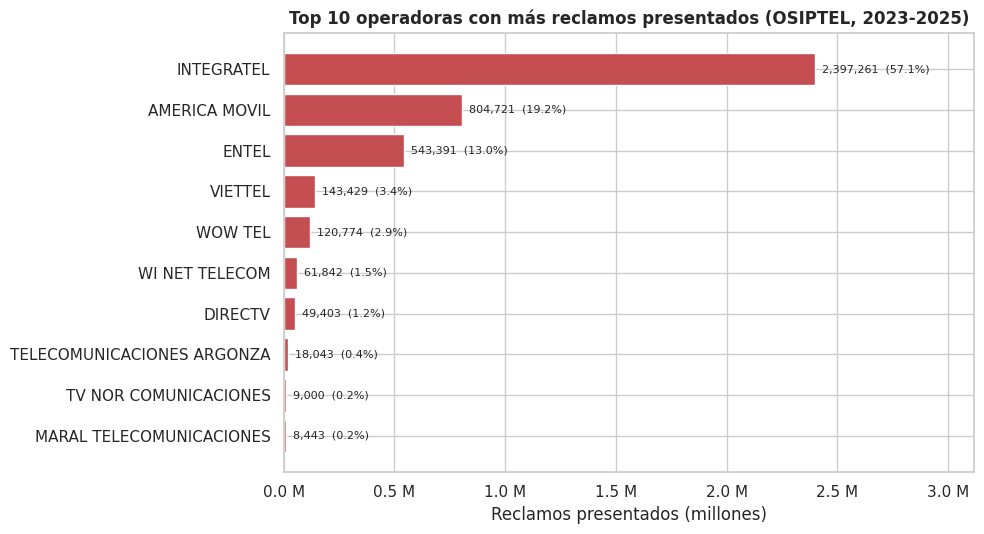

In [17]:
# ============================================================
# GRÁFICO 1 (P1): Top 10 operadoras con más reclamos
# ============================================================
top10 = df_empresa.head(10).sort_values('reclamos_totales')
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.barh(top10['empresa_norm'], top10['reclamos_totales'], color='#C44E52')
for i, v in enumerate(top10['reclamos_totales']):
    ax.text(v, i, f'  {v:,.0f}  ({v / total_reclamos * 100:.1f}%)', va='center', fontsize=8)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x/1e6:.1f} M'))
ax.set_xlim(0, top10['reclamos_totales'].max() * 1.3)
ax.set_title('Top 10 operadoras con más reclamos presentados (OSIPTEL, 2023-2025)', fontweight='bold')
ax.set_xlabel('Reclamos presentados (millones)')
plt.tight_layout(); plt.show()

**Interpretación:** Integratel, que antes era conocida como Telefónica o Movistar, concentra más de la mitad de todos los reclamos registrados, con 2,4 millones aprox. Muy por detrás está América Móvil, que representa a Claro y Entel.

Esto demuestra que los reclamos están concentrados en unas cuantas empresas, ya que las 5 principales acumulan la gran mayoría. Esto tambien refleja que el mercado de telecomunicaciones en el Perú está dominado por un grupo reducido de operadores.

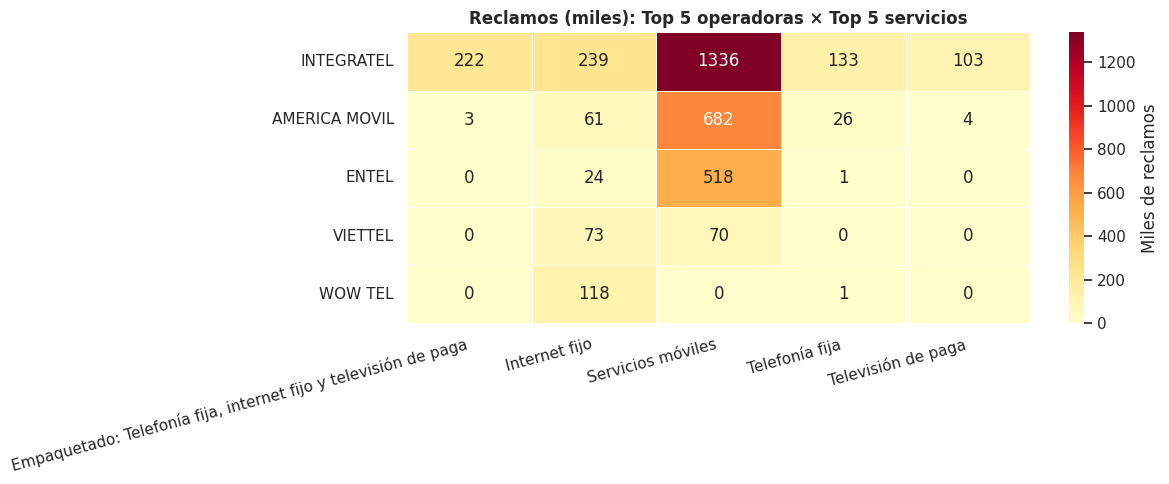

In [18]:
# ============================================================
# GRÁFICO 2 (P2): Top 5 operadoras × Top 5 servicios
# ============================================================
top_emp = df_empresa.head(5)['empresa_norm']
top_serv = df_merged.groupby('Servicio involucrado')[COL_REC].sum().nlargest(5).index
matriz = (df_merged[df_merged['empresa_norm'].isin(top_emp) & df_merged['Servicio involucrado'].isin(top_serv)]
          .pivot_table(index='empresa_norm', columns='Servicio involucrado', values=COL_REC,
                       aggfunc='sum', fill_value=0).loc[top_emp])
plt.figure(figsize=(12, 5))
sns.heatmap(matriz / 1000, annot=True, fmt='.0f', cmap='YlOrRd', linewidths=.5,
            cbar_kws={'label': 'Miles de reclamos'})
plt.title('Reclamos (miles): Top 5 operadoras × Top 5 servicios', fontweight='bold')
plt.xlabel(''); plt.ylabel(''); plt.xticks(rotation=15, ha='right')
plt.tight_layout(); plt.show()

**Interpretación: ** Este heatmap muestra que los servicios móviles concentran la mayor cantidad de reclamos, principalmente de Integratel, América Móvil y Entel.

Por otro lado, el internet fijo es el segundo servicio con más reclamos y destacan empresas como WOW.

Es decir, los principales problemas están en los servicios móviles, pero el internet fijo tambíen concentra una cantidad considerable de reclamos.

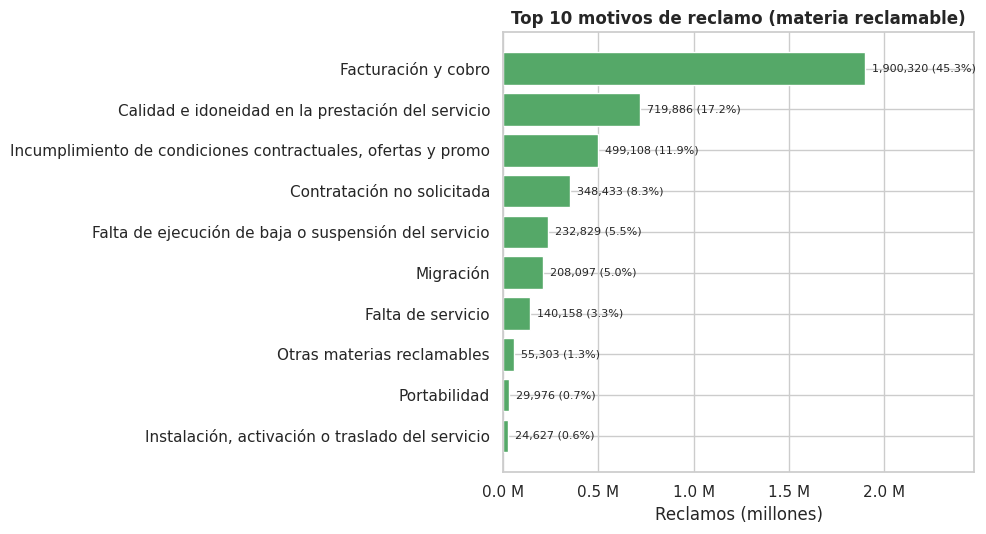

In [19]:
# ============================================================
# GRÁFICO 3 (P2): Top 10 motivos de reclamo
# ============================================================
motivos = (df_merged.groupby('Materia reclamable')[COL_REC].sum().nlargest(10).sort_values())
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.barh(motivos.index.str.slice(0, 60), motivos.values, color='#55A868')
for i, v in enumerate(motivos.values):
    ax.text(v, i, f'  {v:,.0f} ({v / total_reclamos * 100:.1f}%)', va='center', fontsize=8)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x/1e6:.1f} M'))
ax.set_xlim(0, motivos.max() * 1.3)
ax.set_title('Top 10 motivos de reclamo (materia reclamable)', fontweight='bold')
ax.set_xlabel('Reclamos (millones)')
plt.tight_layout(); plt.show()

**Interpretación:** El pricnipal motivo de reclamo en este caso es la facturación y el cobro con casi 1.9 millones de casos.

Esto refleja que el descontento de los usuarios se debe a problemas de cobros, tarifas y facturación.

La solución podría ser reducir muchos reclamos mejorando sus procesos de cobro y atención al cliente, sin tener que realizar inversiones millonarias en infraestructura.

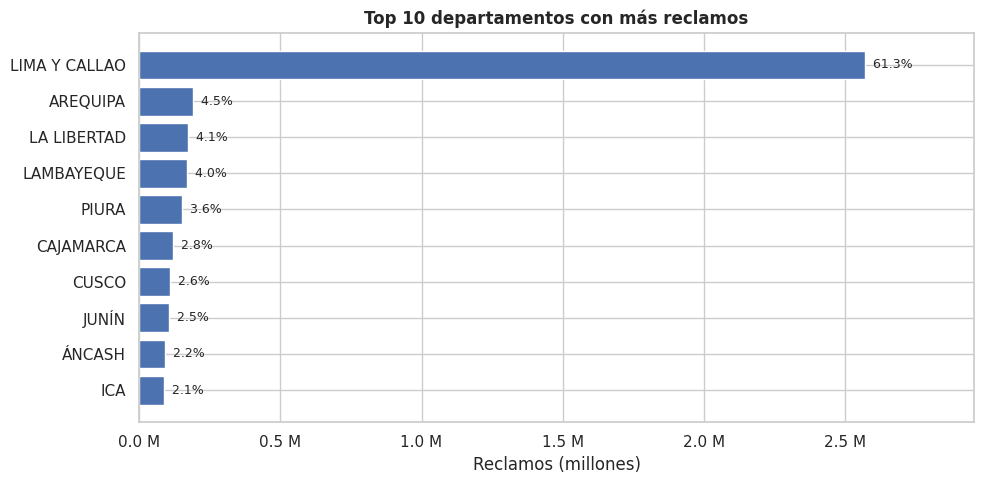

In [20]:
# ============================================================
# GRÁFICO 4 (P3): Top 10 departamentos
# ============================================================
zona = df_merged.groupby('Departamento')[COL_REC].sum().nlargest(10).sort_values()
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(zona.index, zona.values, color='#4C72B0')
for i, v in enumerate(zona.values):
    ax.text(v, i, f'  {v / total_reclamos * 100:.1f}%', va='center', fontsize=9)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x/1e6:.1f} M'))
ax.set_xlim(0, zona.max() * 1.15)
ax.set_title('Top 10 departamentos con más reclamos', fontweight='bold')
ax.set_xlabel('Reclamos (millones)')
plt.tight_layout(); plt.show()

**Interpretación:** En este gráfico de barras de demuestra que Lima y el Callao concetran más de la mitad de los reclamos del Perú seguido por otros departamentos en menor medida.

Esto no necesariamente significa que Lima y el Callao tengan la peor calidd de servicio, ya que hay que considerar que ahí habitan muchísimas más personas.

Por eso si tenemos que identificar donde hay verdaderos problemas, hay que analizar qué servicios y motios generan más reclamos.

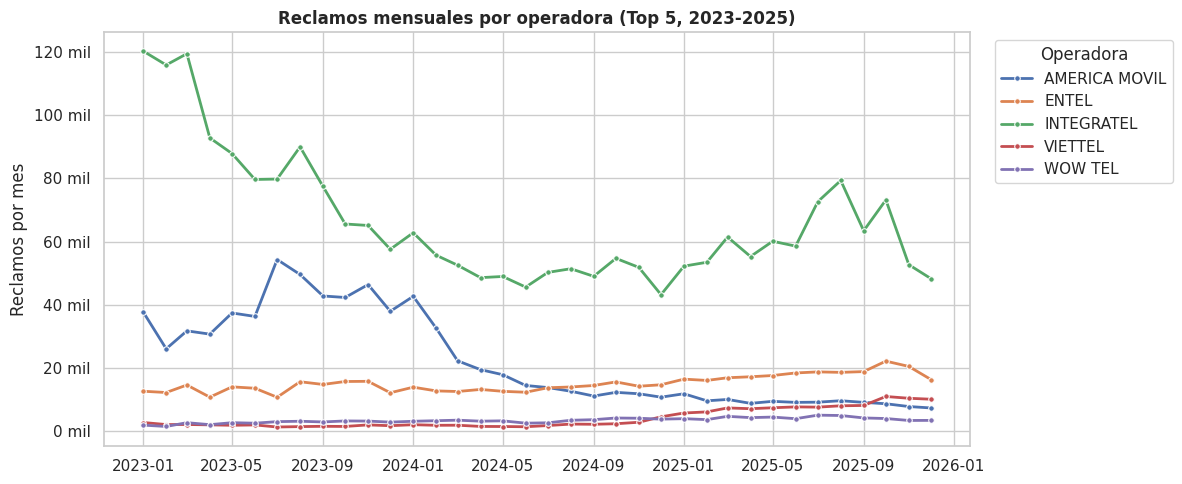

In [21]:
# ============================================================
# GRÁFICO 5 (P4): Evolución mensual por operadora (Top 5)
# ============================================================
serie_emp = (df_merged[df_merged['empresa_norm'].isin(top_emp)]
             .groupby(['empresa_norm', 'Mes'])[COL_REC].sum().reset_index())
plt.figure(figsize=(12, 5))
sns.lineplot(data=serie_emp, x='Mes', y=COL_REC, hue='empresa_norm', marker='o', markersize=4, linewidth=2)
plt.gca().yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x/1000:.0f} mil'))
plt.title('Reclamos mensuales por operadora (Top 5, 2023-2025)', fontweight='bold')
plt.xlabel(''); plt.ylabel('Reclamos por mes')
plt.legend(title='Operadora', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout(); plt.show()

**Interpretación:** Este gráfico nos muestra cómo han evolucionado los reclamos de estas 5 operadoras entre 2023 y 2025.

- Integratel: Es la que tiene más reclamos durante este intervalo de tiempo, sin embargo, sus cifras han variado, de 120 mil reclamos por mes en el 2023 a 45 mil en el 2024, aunque subión a 80 mil en el 2025.

- América Móvil: Esta empresa es la que más ha mejorado, ya que sus reclamos bajaron considerablementem pasando de unos 54 mil mensuales a menos de 10 mil a fines del 2024.

- Entel: Esta empresa es el caso contrario, ya que sus reclamos aumentaron, aunque muy poco, de 12 mil a 20 mil, sin embargo, es importante mencionar que superó a América Móvil a mediados del 2024.

- Bitel: También tuvo un aumento de reclamos aunque muy pocos en términos absolutos, pasando de unos 2 mil a 10 mil

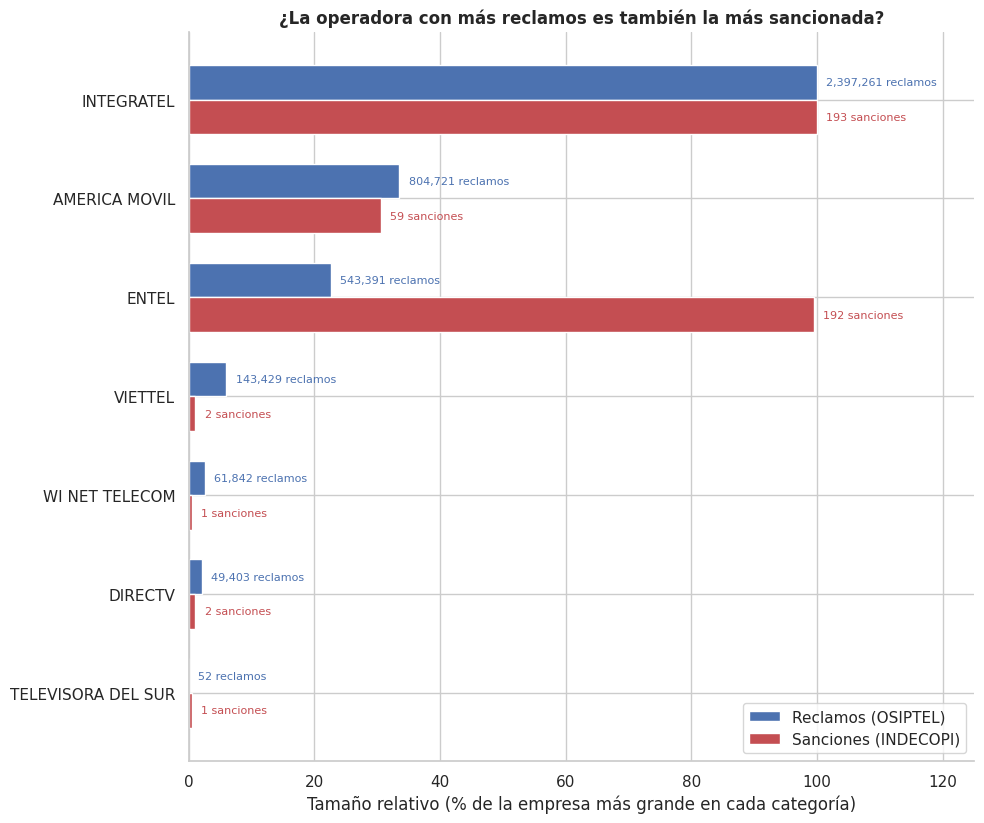

In [22]:
# ============================================================
# GRÁFICO 6: Reclamos vs sanciones por operadora (tamaño relativo)
# ============================================================
df_plot = df_empresa.dropna(subset=['total_sanciones']).copy()
df_plot['pct_reclamos']  = df_plot['reclamos_totales'] / df_plot['reclamos_totales'].max() * 100
df_plot['pct_sanciones'] = df_plot['total_sanciones'] / df_plot['total_sanciones'].max() * 100
df_plot = df_plot.sort_values('reclamos_totales')

fig, ax = plt.subplots(figsize=(10, max(5, 1.2 * len(df_plot))))
y, alto = np.arange(len(df_plot)), 0.35
ax.barh(y + alto/2, df_plot['pct_reclamos'],  height=alto, color='#4C72B0', label='Reclamos (OSIPTEL)')
ax.barh(y - alto/2, df_plot['pct_sanciones'], height=alto, color='#C44E52', label='Sanciones (INDECOPI)')
for i, f in enumerate(df_plot.itertuples()):
    ax.text(f.pct_reclamos + 1.5, i + alto/2, f'{f.reclamos_totales:,.0f} reclamos', va='center', fontsize=8, color='#4C72B0')
    ax.text(f.pct_sanciones + 1.5, i - alto/2, f'{f.total_sanciones:,.0f} sanciones', va='center', fontsize=8, color='#C44E52')
ax.set_yticks(y); ax.set_yticklabels(df_plot['empresa_norm'])
ax.set_xlim(0, 125)
ax.set_xlabel('Tamaño relativo (% de la empresa más grande en cada categoría)')
ax.set_title('¿La operadora con más reclamos es también la más sancionada?', fontweight='bold')
ax.legend(loc='lower right')
for s in ['top', 'right']: ax.spines[s].set_visible(False)
plt.tight_layout(); plt.show()

**Interpretación:** Ete grafico refleja la relación entre la cantidad de reclamos y las sanciones que recibió cada operadora.

Integratel lidera ambos aspectos, con aprox 2,4 millones de reclamos y 193 sanciones, concentrando la mayor cantidad de estos aspectos (reclamos y sanciones)

Aunque el caso más llamativo es Entel, porque tiene aprox 543 mil reclamos pero acumula 192 sanciones, casi la misma cantidad de sanciones que Integratel.

La que sale "bien parada" es América Móvil ya que presenta mucho menos reclamos y apenas 59 sanciones.

Esto quiere decir que tener más reclamos es igual a más sanciones, pero no necesariamente en la misma proporción, esto último se prueba con el caso de Entel.

,empresa_norm,reclamos_totales,total_sanciones,monto_uit,sanciones_x_100k,multa_soles,soles_x_reclamo
31,ENTEL,543391.0,192.0,81.93,35.33,438325.5,0.81
42,INTEGRATEL,2397261.0,193.0,326.75,8.05,1748112.5,0.73
0,AMERICA MOVIL,804721.0,59.0,61.84,7.33,330844.0,0.41
25,DIRECTV,49403.0,2.0,6.65,4.05,35577.5,0.72
80,WI NET TELECOM,61842.0,1.0,0.00,1.62,0.0,0.00
76,VIETTEL,143429.0,2.0,6.98,1.39,37343.0,0.26


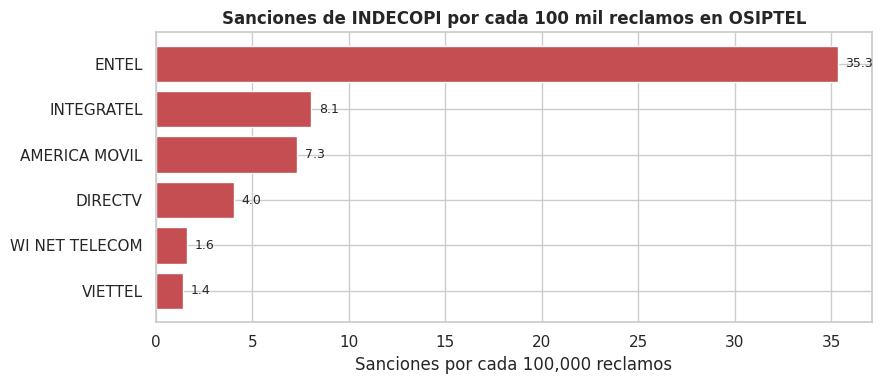

In [23]:
# ============================================================
# GRÁFICO 7: Riesgo regulatorio POR RECLAMO
# ============================================================
UIT_REF = 5350   # UIT 2025 en soles (referencial, para expresar las multas en S/)

df_empresa['sanciones_x_100k'] = df_empresa['total_sanciones'].fillna(0) / df_empresa['reclamos_totales'] * 1e5
df_empresa['multa_soles']      = df_empresa['monto_uit'].fillna(0) * UIT_REF

riesgo = (df_empresa.dropna(subset=['total_sanciones'])
          .query('reclamos_totales >= 10000')            # evita ratios inestables en empresas pequeñas
          .assign(soles_x_reclamo=lambda d: d['multa_soles'] / d['reclamos_totales'])
          .sort_values('sanciones_x_100k', ascending=False))
display(riesgo[['empresa_norm', 'reclamos_totales', 'total_sanciones', 'monto_uit',
                'sanciones_x_100k', 'multa_soles', 'soles_x_reclamo']].round(2))

fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(riesgo['empresa_norm'], riesgo['sanciones_x_100k'], color='#C44E52')
ax.invert_yaxis()
for i, v in enumerate(riesgo['sanciones_x_100k']):
    ax.text(v + 0.4, i, f'{v:.1f}', va='center', fontsize=9)
ax.set_title('Sanciones de INDECOPI por cada 100 mil reclamos en OSIPTEL', fontweight='bold')
ax.set_xlabel('Sanciones por cada 100,000 reclamos')
plt.tight_layout(); plt.show()

**Interpretación: ** En este gráfico analizamos el riesgo de cada operadora en relación con la cantidad de reclamos que recibe, aunque encontramos una diferencia importante:

Entel regista aprox 35 sanciones por cada 100 mil reclamos, mientras que Integratel registra unas 8 y América Móvil 7, es decir, que Entel acumula casi 5 veces más sanciones por reclamo a diferencia de estas 2 empresas.

Pero si hablamos del monto total de multas, Integratel tiene más riesgo económico, con casi 2 millones de sole por reclamo.

Es decir, no bastnat con analizar cuantos reclamos hay por empresa, también se tiene que observar cuántas sanciones acumula que estén relacionados a los reclamos.



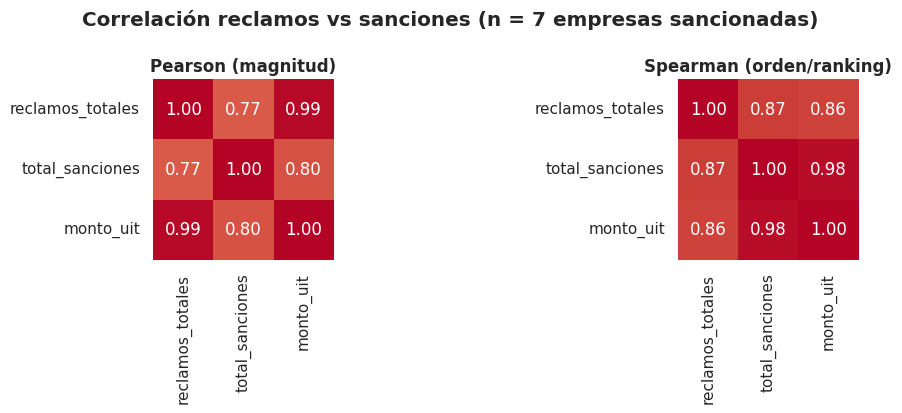

ADVERTENCIA: n = 7 empresas -> resultado indicativo, no concluyente.


In [24]:
# ============================================================
# Correlación reclamos vs exposición regulatoria (solo empresas sancionadas)
# ============================================================
base_corr = df_empresa.dropna(subset=['total_sanciones'])
vars_corr = ['reclamos_totales', 'total_sanciones', 'monto_uit']
pearson  = base_corr[vars_corr].corr()
spearman = base_corr[vars_corr].corr(method='spearman')

fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
for a, m, t in [(ax[0], pearson, 'Pearson (magnitud)'), (ax[1], spearman, 'Spearman (orden/ranking)')]:
    sns.heatmap(m, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1, square=True, ax=a, cbar=False)
    a.set_title(t, fontweight='bold')
plt.suptitle(f'Correlación reclamos vs sanciones (n = {len(base_corr)} empresas sancionadas)', fontweight='bold')
plt.tight_layout(); plt.show()
print(f"ADVERTENCIA: n = {len(base_corr)} empresas -> resultado indicativo, no concluyente.")

**Interpretación:** Los resultados muestran que existe una correlación muy fuerte entre los reclamos y el monto total de multas, con una correlación de 0.99. En cambio, a relación con el número de sanciones es menor, pero sigue siendo fuerte con 0.75.

Esto quiere decir que las empresas que reciben más reclamos generalmente pagan más en multas, pero no significa que necesariamente reciban más sanciones proporcionalmente hablando, ya que Entel rompe parcialmente eta tendencia.

Esto quiere decir de que la cantidad de reclamos ayuda a explicar cuánto puede pagar una empresa en multas, pero no necesariamente cuántas sanciones recibirá.

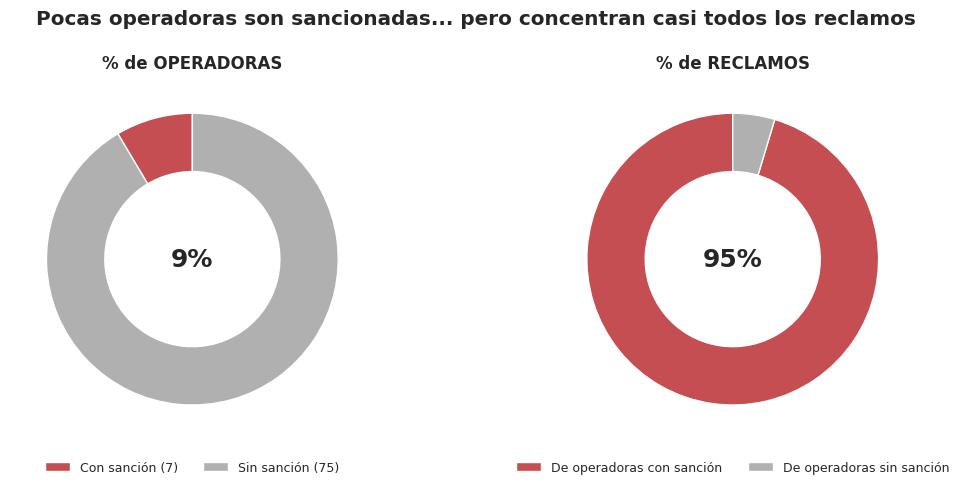

In [25]:
# ============================================================
# GRÁFICO 8 (P6): ¿Qué proporción de operadoras llega a sanción formal?
# ============================================================
n_con = int(df_empresa['total_sanciones'].notna().sum()); n_sin = len(df_empresa) - n_con
rec_con = df_empresa.loc[df_empresa['total_sanciones'].notna(), 'reclamos_totales'].sum() / total_reclamos * 100

fig, ax = plt.subplots(1, 2, figsize=(11, 5))
for a, vals, lab, t in [
    (ax[0], [n_con, n_sin], [f'Con sanción ({n_con})', f'Sin sanción ({n_sin})'], '% de OPERADORAS'),
    (ax[1], [rec_con, 100 - rec_con], ['De operadoras con sanción', 'De operadoras sin sanción'], '% de RECLAMOS')]:
    w, _ = a.pie(vals, colors=['#C44E52', '#B0B0B0'], startangle=90, wedgeprops=dict(width=0.4, edgecolor='white'))
    a.text(0, 0, f'{vals[0] / sum(vals) * 100:.0f}%', ha='center', va='center', fontsize=18, fontweight='bold')
    a.legend(w, lab, loc='lower center', bbox_to_anchor=(0.5, -0.12), ncol=2, frameon=False, fontsize=9)
    a.set_title(t, fontweight='bold')
plt.suptitle('Pocas operadoras son sancionadas... pero concentran casi todos los reclamos', fontweight='bold')
plt.tight_layout(); plt.show()

**Interpretación:** De las 82 operadoras observadas, solo 7 tienen sanciones registradas en INDECOPI, es decir un 8.5% aprox. Aunque también, 7 empresas concentran cerca del 95% de todos los reclamos.

Esto quiere decir que los problemas y sanciones no están distribuidos de manera uniforme, sino que están en las empresas más grandes (que tienen más usuarios)

OSIPTEL debería prestar atención a las grandes operadoras enfocándose en mejorar la gestión de sus reclamos y evitar que se acumulen.

### Respuesta a la pregunta huérfana

**Sí, pero no de forma proporcional.**
- La operadora con más reclamos, **Integratel (ex Telefónica)**, también es la **más sancionada**: 193 sanciones y 326.75 UIT (≈ S/ 1.75 millones a valor UIT 2025), más que Entel (192 sanciones; 81.93 UIT) y América Móvil (59; 61.84 UIT).
- Solo una minoría de operadoras tiene sanciones, pero esas pocas concentran casi todos los reclamos del mercado (gráfico 8).
- **El insight no obvio está en las sanciones por reclamo:** Entel registra **≈ 35 sanciones por cada 100 mil reclamos**, frente a ≈ 8 de Integratel y ≈ 7 de América Móvil, es decir, **entre 4 y 5 veces más**. Su riesgo regulatorio no viene solo de *cuántos* reclamos recibe.

**El enriquecimiento cambió la conclusión.** Sin corregir el alias, Integratel figuraba "sin sanciones" y la conclusión habría sido la contraria: *"el volumen de reclamos no predice las sanciones"*.

#¿Qué combinación de servicio, motivo y zona concentra los reclamos?

In [26]:
# ============================================================
# Combinaciones servicio × materia × departamento
# ============================================================
df_merged['materia_principal'] = (df_merged['Materia reclamable'].astype(str).str.split('|').str[0].str.strip())

combos = (df_merged.groupby(['Servicio involucrado', 'materia_principal', 'Departamento'])[COL_REC]
          .sum().sort_values(ascending=False).reset_index())
combos['% del total'] = combos[COL_REC] / total_reclamos * 100
combos['% acumulado'] = combos['% del total'].cumsum()

n_combos_50 = int((combos['% acumulado'] < 50).sum() + 1)
print(f"Combinaciones posibles con reclamos: {len(combos):,}")
print(f"Solo {n_combos_50} combinaciones ({n_combos_50 / len(combos) * 100:.2f}%) concentran el 50% de los reclamos.\n")
display(combos.head(15).round(2))

Combinaciones posibles con reclamos: 2,716
Solo 17 combinaciones (0.63%) concentran el 50% de los reclamos.



,Servicio involucrado,materia_principal,Departamento,N° de Reclamos Presentados,% del total,% acumulado
0,Servicios móviles,Facturación y cobro,LIMA Y CALLAO,819693.0,19.54,19.54
1,Servicios móviles,"Incumplimiento de condiciones contractuales, o...",LIMA Y CALLAO,221623.0,5.28,24.82
2,Servicios móviles,Contratación no solicitada,LIMA Y CALLAO,144429.0,3.44,28.26
3,Internet fijo,Calidad e idoneidad en la prestación del servicio,LIMA Y CALLAO,143387.0,3.42,31.68
4,Servicios móviles,Calidad e idoneidad en la prestación del servicio,LIMA Y CALLAO,91555.0,2.18,33.86
5,Servicios móviles,Migración,LIMA Y CALLAO,90850.0,2.17,36.03
6,Internet fijo,Facturación y cobro,LIMA Y CALLAO,88321.0,2.11,38.14
7,Servicios móviles,Facturación y cobro,AREQUIPA,69999.0,1.67,39.80
8,Servicios móviles,Facturación y cobro,LAMBAYEQUE,63888.0,1.52,41.33
9,Telefonía fija,Calidad e idoneidad en la prestación del servicio,LIMA Y CALLAO,60874.0,1.45,42.78


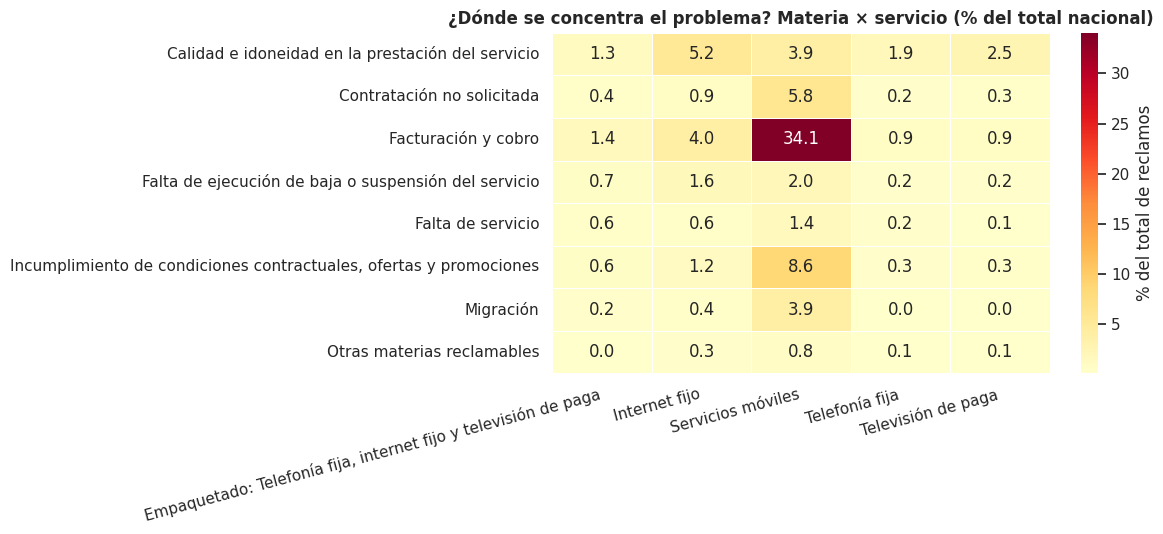

Índice regiones / Lima por materia (>1 = pesa más en regiones):


,índice
materia_principal,
Migración,1.10
Facturación y cobro,1.09
Otras materias reclamables,0.96
Falta de ejecución de baja o suspensión del servicio,0.95
Calidad e idoneidad en la prestación del servicio,0.93
"Incumplimiento de condiciones contractuales, ofertas y promociones",0.91
Contratación no solicitada,0.90
Falta de servicio,0.76


In [27]:
# ============================================================
# Mapa de calor materia × servicio (todo el país) y peso fuera de Lima
# ============================================================
top_mat = df_merged.groupby('materia_principal')[COL_REC].sum().nlargest(8).index
mat_serv = (df_merged[df_merged['materia_principal'].isin(top_mat) & df_merged['Servicio involucrado'].isin(top_serv)]
            .pivot_table(index='materia_principal', columns='Servicio involucrado', values=COL_REC, aggfunc='sum', fill_value=0))
plt.figure(figsize=(12, 5.5))
sns.heatmap(mat_serv / total_reclamos * 100, annot=True, fmt='.1f', cmap='YlOrRd', linewidths=.5,
            cbar_kws={'label': '% del total de reclamos'})
plt.title('¿Dónde se concentra el problema? Materia × servicio (% del total nacional)', fontweight='bold')
plt.xlabel(''); plt.ylabel(''); plt.xticks(rotation=15, ha='right')
plt.tight_layout(); plt.show()

# ¿Qué materias pesan más en regiones que en Lima? (índice > 1 = sobre-representada en regiones)
es_lima = df_merged['Departamento'].astype(str).str.upper().str.contains('LIMA')
peso_lima = df_merged[es_lima].groupby('materia_principal')[COL_REC].sum(); peso_lima /= peso_lima.sum()
peso_reg  = df_merged[~es_lima].groupby('materia_principal')[COL_REC].sum(); peso_reg /= peso_reg.sum()
indice_reg = (peso_reg / peso_lima).loc[top_mat].sort_values(ascending=False).round(2)
print("Índice regiones / Lima por materia (>1 = pesa más en regiones):")
display(indice_reg.to_frame('índice'))

**Interpretación: ** En este análisis vimos que el principal problema se concentra en la facturación y cobros que representan el 34% de todos los reclamos del Perú.

También destacan problemas con las condiciones de los contratos, ofertas y promociones, también las contrataciones que los usuarios no solicitarion.

Todo esto en combinación demuestra que la mayoría de los reclamos de servicios móviles están relacionados con problemas comerciales y no necesariamente con fallas técnicas.

Con respecto a Lima y las demás regiones:
Lo resultados muestran que el tipo de reclamos es muy parecido en todo el Perú, aunque Lima concentra la mayoría de los casos es por la cantidad de usuarios.

Con toda esto a la mano, la solución podría ser enfocarse en mejorar los procesos de facturación, cobros y comunicación de ofertas en los servicios móviles, con esto podrían reducirse los reclamos en más de un 40%.

#
#Serie de tiempo: descomposición y pronóstico 2026

In [28]:
# ============================================================
# Serie mensual total + descomposición
# ============================================================
from statsmodels.tsa.seasonal import seasonal_decompose

ts_mensual = df_merged.groupby('Mes')[COL_REC].sum().asfreq('MS')    # SIN rellenar
faltantes = ts_mensual[ts_mensual.isna()]
print(f"Meses en la serie: {len(ts_mensual)} | Meses faltantes: {len(faltantes)}")
assert faltantes.empty, f"Faltan meses: {list(faltantes.index)} -> revisar fuente, NO rellenar"

descomposicion = seasonal_decompose(ts_mensual, model='additive', period=12)   # 3 ciclos anuales

var_tend = (descomposicion.trend.dropna().iloc[-1] / descomposicion.trend.dropna().iloc[0] - 1) * 100
print(f"Variación de la tendencia en el periodo: {var_tend:.1f}%")

fmt_miles = mticker.FuncFormatter(lambda x, _: f'{x/1000:.0f} mil')

Meses en la serie: 36 | Meses faltantes: 0
Variación de la tendencia en el periodo: -29.9%


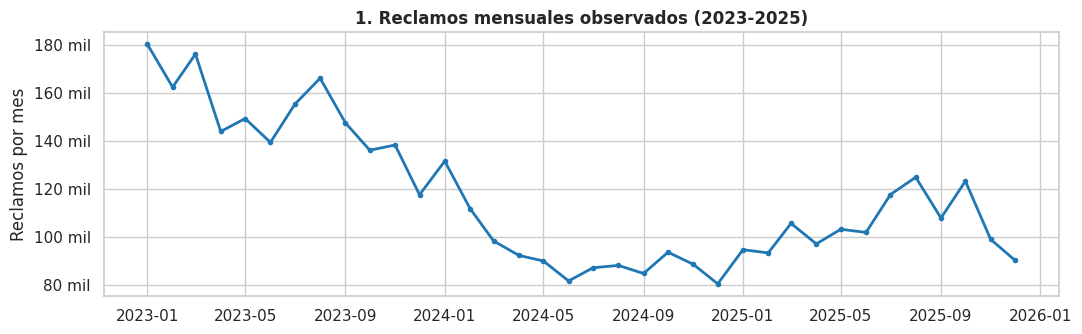

In [29]:
plt.figure(figsize=(11, 3.5))
plt.plot(descomposicion.observed, color='#1f77b4', lw=2, marker='o', markersize=3)
plt.gca().yaxis.set_major_formatter(fmt_miles)
plt.title('1. Reclamos mensuales observados (2023-2025)', fontweight='bold')
plt.ylabel('Reclamos por mes'); plt.xlabel('')
plt.tight_layout(); plt.show()

**Interpretación:** El grafico muestra que los reclamos van desde el 2023, que es su punto más alto, con 180 mil reclamos aprox, aunque esta cifre se redujo hasta 80 mil casos aprox en 2024, en un poco más de 1 año.

Luego en el 2025, los reclamos aumentaron a 125 mil aprox aunque bajaron nuevamente en diciembre.

Esto refleja que los reclamos no tienen un comportamiento constante, sino que consta de subidas y bajadas.

Sin embargo, también sería importante diferenciar las tendencias de los reclamos y de los aumentos, ya que podrían reponder a patrones, por lo que puede ser buena idea "separarlos".

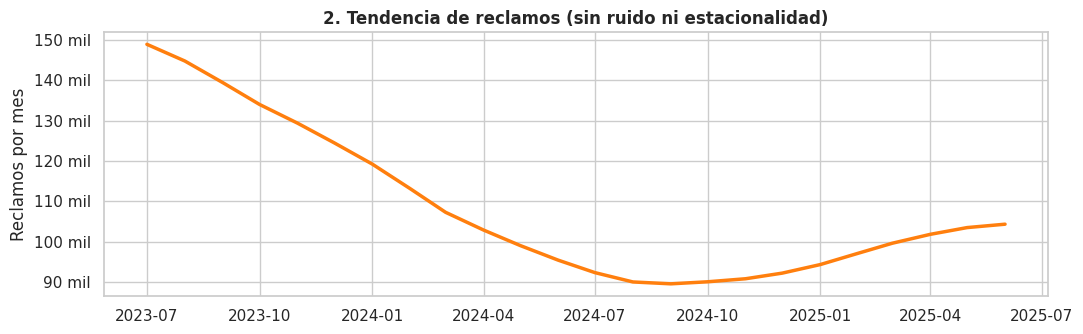

In [30]:
plt.figure(figsize=(11, 3.5))
plt.plot(descomposicion.trend, color='#ff7f0e', lw=2.5)
plt.gca().yaxis.set_major_formatter(fmt_miles)
plt.title('2. Tendencia de reclamos (sin ruido ni estacionalidad)', fontweight='bold')
plt.ylabel('Reclamos por mes'); plt.xlabel('')
plt.tight_layout(); plt.show()

**Interpretación:** Aquí se mestran la tendencia general de los reclamos, eliminando las variacione de cada mes.

Se muestra que lo reclamos disminuyeron aprox un 30% entre 2023 y 2024, pasando de unos 149 mil a unos 90 mil, sin embargo, a partir de septiembre del 2024, los reclamos comenzaron a aumentar de nuevo y para mediados de 2025 ya eran aprox 104 mil casos

Esto quiere decir que la reducción de reclamos no se mantuvo a lo largo del tiempo, además, este aumento coincide con el de Entel y Bitel curiosamente.

Básicamente es una señal de alerta el repunte de reclamos porque demuestra que la mejora no se mantuvo.

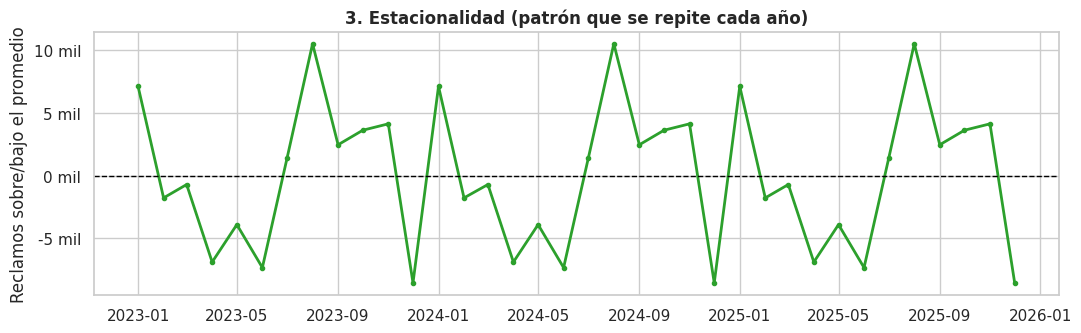

In [31]:
plt.figure(figsize=(11, 3.5))
plt.plot(descomposicion.seasonal, color='#2ca02c', lw=2, marker='o', markersize=3)
plt.axhline(0, color='black', ls='--', lw=1)
plt.gca().yaxis.set_major_formatter(fmt_miles)
plt.title('3. Estacionalidad (patrón que se repite cada año)', fontweight='bold')
plt.ylabel('Reclamos sobre/bajo el promedio'); plt.xlabel('')
plt.tight_layout(); plt.show()

**Interpretación:**

En este gráfico se observa un patrón que se repite 3 veces.

El mes má "crítico" es agosto que regitra aprox. 10.5 mil reclamos por encima del promedio, aunque tambien destaca el intervalo de septiembre a noviembre.

El caso contrario es diciembre, abril y junio, esto permite identificar que estos meses suelen ser los puntos más bajos.

Una explicación lógica podría ser que después de fechas festivas como navidad o fiestras patrias y promociones de verano, los usuarios presentan reclamos por cobros que no esperaban, aunque esto solo es una hpótesis.

Lo importnte sería prepararse para agosto reforzando la atención al cliente para prevenir el aumento de reclamos.

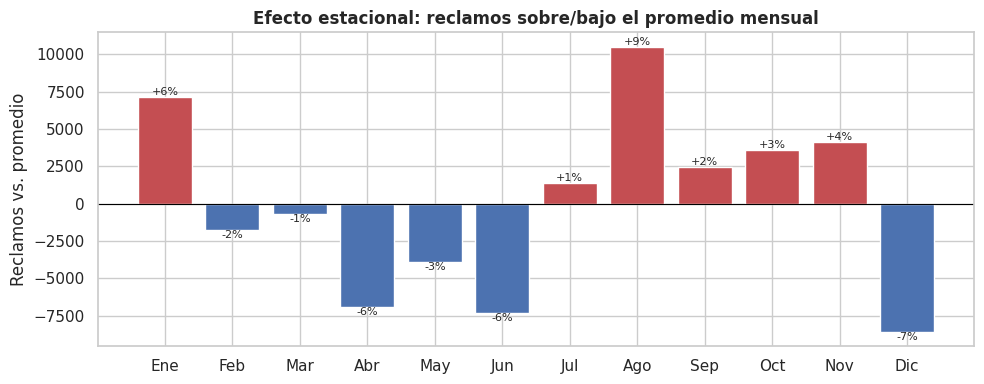

Meses críticos (de mayor a menor): ['Ago', 'Ene', 'Nov', 'Oct', 'Sep', 'Jul']


In [32]:
# ============================================================
# Efecto estacional promedio por mes
# ============================================================
estac = descomposicion.seasonal.groupby(descomposicion.seasonal.index.month).mean()
MESES = ['Ene','Feb','Mar','Abr','May','Jun','Jul','Ago','Sep','Oct','Nov','Dic']
nivel_medio = ts_mensual.mean()

plt.figure(figsize=(10, 4))
plt.bar(MESES, estac.values, color=['#C44E52' if v > 0 else '#4C72B0' for v in estac.values])
for i, v in enumerate(estac.values):
    plt.text(i, v, f'{v / nivel_medio * 100:+.0f}%', ha='center', va='bottom' if v > 0 else 'top', fontsize=8)
plt.axhline(0, color='black', lw=0.8)
plt.title('Efecto estacional: reclamos sobre/bajo el promedio mensual', fontweight='bold')
plt.ylabel('Reclamos vs. promedio')
plt.tight_layout(); plt.show()

meses_criticos = [MESES[m - 1] for m in estac[estac > 0].sort_values(ascending=False).index]
print("Meses críticos (de mayor a menor):", meses_criticos)

**Interpretación:**
Acá se muestra que los reclamos siguen un comportamiento ligeramente "predecible" en el año.

Agosto es el mes más critico, con un 9% má de reclamos que el promedio mensual, le sigue enero con un 6%. El caso contrario es diciembre que tiene un 7% menos de reclamos, seguido de abril y junio.

La diferencia entre agosto y diciembre es de aprox 19 mil reclamos, lo que demuestra una variación considerable según la época del año.

OSIPTEL puede aprovehcar esto para realizar supervisiones y exigir a las operadoras que refuercen su antención al cliente antes de agosto y enero.

# Hallazgos del EDA

1. **Concentración fuerte del problema.** El Top 5 de operadoras acumula el 95.6% de los reclamos del periodo (KPI 2). El mercado de reclamos replica la estructura oligopólica del mercado de telecomunicaciones.

2. **La tasa de cruce por empresa es inferior al 70%, y es un hallazgo, no un defecto.** Solo cruza el 8.5% de las operadoras, pero ese grupo cubre el 91.4% de las filas y el 95.4% de los reclamos. OSIPTEL registra decenas de operadoras locales y regionales; INDECOPI solo registra a los proveedores sancionados, que son casi exclusivamente las grandes.

3. **La mayoría de las operadoras no tiene sanción formal (KPI 3).** El volumen por sí solo es un predictor incompleto del riesgo regulatorio: WOW Tel supera los 120 mil reclamos sin ninguna sanción en el ranking.

4. **Outliers relevantes en las sanciones (ver EDA 2).** Unas pocas empresas concentran montos en UIT muy por encima del rango intercuartílico; no se eliminan porque son el objeto de estudio.

5. **Concentración geográfica en Lima**, coherente con la densidad de usuarios. Para comparar incidencia entre regiones haría falta normalizar por número de líneas.

6. **Estacionalidad clara en la serie mensual:** picos en agosto y enero, valles en diciembre, abril y junio. Se usa en el pronóstico de 2026.

,Modelo,MAPE 2025 (%)
2,Sin tendencia,18.1
0,Tendencia lineal,18.3
3,Ingenuo estacional,18.8
1,Tendencia amortiguada,27.1


Versión elegida: Sin tendencia (MAPE 18.1% vs ingenuo 18.8%)


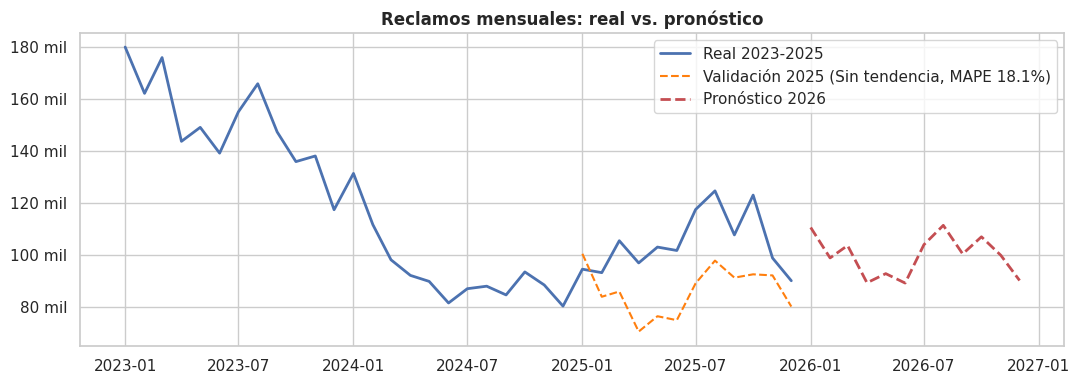

,reclamos_pronosticados
2026-01-01,110628.0
2026-02-01,98902.0
2026-03-01,103692.0
2026-04-01,89328.0
2026-05-01,92852.0
2026-06-01,89222.0
2026-07-01,103993.0
2026-08-01,111453.0
2026-09-01,100438.0
2026-10-01,107037.0


Total pronosticado 2026: 1,197,667 vs 2025 real: 1,257,286 (-4.7%)


In [33]:
# ============================================================
# Pronóstico Holt-Winters: se elige la versión con menor error en 2025
# ============================================================
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.metrics import mean_absolute_percentage_error

train_ts, test_ts = ts_mensual[:'2024-12-01'], ts_mensual['2025-01-01':]
pred_naive_est = ts_mensual.shift(12)['2025-01-01':]          # ingenuo: = mismo mes del año anterior
mape_naive = mean_absolute_percentage_error(test_ts, pred_naive_est) * 100

versiones = {'Tendencia lineal':      dict(trend='add', damped_trend=False),
             'Tendencia amortiguada': dict(trend='add', damped_trend=True),
             'Sin tendencia':         dict(trend=None)}
comparacion, preds = [], {}
for nombre, params in versiones.items():
    m = ExponentialSmoothing(train_ts, seasonal='add', seasonal_periods=12, **params).fit()
    preds[nombre] = m.forecast(len(test_ts))
    comparacion.append({'Modelo': nombre,
                        'MAPE 2025 (%)': round(mean_absolute_percentage_error(test_ts, preds[nombre]) * 100, 1)})
comparacion.append({'Modelo': 'Ingenuo estacional', 'MAPE 2025 (%)': round(mape_naive, 1)})
comparacion = pd.DataFrame(comparacion).sort_values('MAPE 2025 (%)')
display(comparacion)

mejor_hw = comparacion[comparacion['Modelo'] != 'Ingenuo estacional'].iloc[0]['Modelo']
pred_hw, mape_hw = preds[mejor_hw], comparacion.set_index('Modelo').loc[mejor_hw, 'MAPE 2025 (%)']
print(f"Versión elegida: {mejor_hw} (MAPE {mape_hw}% vs ingenuo {mape_naive:.1f}%)")

# Reentrenar con los 36 meses y pronosticar 2026
hw_full = ExponentialSmoothing(ts_mensual, seasonal='add', seasonal_periods=12, **versiones[mejor_hw]).fit()
forecast_2026 = hw_full.forecast(12).rename('reclamos_pronosticados')

plt.figure(figsize=(11, 4))
plt.plot(ts_mensual, label='Real 2023-2025', lw=2)
plt.plot(pred_hw, '--', label=f'Validación 2025 ({mejor_hw}, MAPE {mape_hw}%)', color='#ff7f0e')
plt.plot(forecast_2026, '--', label='Pronóstico 2026', color='#C44E52', lw=2)
plt.gca().yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x/1000:.0f} mil'))
plt.title('Reclamos mensuales: real vs. pronóstico', fontweight='bold')
plt.legend(); plt.tight_layout(); plt.show()

display(forecast_2026.round(0).to_frame())
print(f"Total pronosticado 2026: {forecast_2026.sum():,.0f} vs 2025 real: {test_ts.sum():,.0f} "
      f"({(forecast_2026.sum() / test_ts.sum() - 1) * 100:+.1f}%)")

**Interpretación:** El modelo sin tendencia fue el más "preciso", con un error del 18.1%, para 2026 se proyectan entre 89 y 111 mil reclamos mensuales, con picos en enero y agosto.

Como se mencionó anterior OSIPTEL debería preparse para dichos meses y reforzar su supervisión.

#Modelo supervisado: reclamos por empresa-mes, variable objetivo del caso

In [34]:
# ============================================================
# Paso 1: Panel empresa-mes
# ============================================================
import statsmodels.formula.api as smf
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

panel = df_merged.groupby(['empresa_norm', 'Mes'])[COL_REC].sum().reset_index(name='reclamos_mes')
meses_emp = panel.groupby('empresa_norm')['Mes'].nunique()
panel = panel[panel['empresa_norm'].isin(meses_emp[meses_emp == 36].index)]   # panel completo, sin huecos

panel = panel.merge(df_empresa[['empresa_norm', 'total_sanciones']], on='empresa_norm', how='left')
panel['total_sanciones'] = panel['total_sanciones'].fillna(0)

panel = panel.sort_values(['empresa_norm', 'Mes'])
panel['log_reclamos']  = np.log1p(panel['reclamos_mes'])
panel['log_sanciones'] = np.log1p(panel['total_sanciones'])
g = panel.groupby('empresa_norm')['log_reclamos']
panel['lag1']    = g.shift(1)
panel['media3']  = g.transform(lambda s: s.shift(1).rolling(3).mean())
panel['impulso'] = panel['lag1'] - panel['media3']                 # ¿venía subiendo o bajando?
panel['mes_del_año'] = panel['Mes'].dt.month
panel['t'] = (panel['Mes'].dt.year - 2023) * 12 + panel['Mes'].dt.month
panel = panel.dropna(subset=['lag1', 'media3'])

train = panel[panel['Mes'] <= '2024-12-01']
test  = panel[panel['Mes'] >= '2025-01-01']

print(f"Empresas en el panel: {panel['empresa_norm'].nunique()} de {meses_emp.size} (presentes los 36 meses)")
print(f"Train: {train['Mes'].min():%Y-%m} a {train['Mes'].max():%Y-%m} ({len(train)} filas)")
print(f"Test : {test['Mes'].min():%Y-%m} a {test['Mes'].max():%Y-%m} ({len(test)} filas)")
print("Control - sanciones de INTEGRATEL en el panel:",
      panel.loc[panel['empresa_norm'] == 'INTEGRATEL', 'total_sanciones'].max())

Empresas en el panel: 23 de 82 (presentes los 36 meses)
Train: 2023-04 a 2024-12 (483 filas)
Test : 2025-01 a 2025-12 (276 filas)
Control - sanciones de INTEGRATEL en el panel: 193.0


In [35]:
# ============================================================
# MODELO 1 - Regresión lineal (OLS): ¿qué se asocia al nivel de reclamos?
# ============================================================
# Errores estándar agrupados por empresa: el panel repite 21 meses por operadora y las
# sanciones son un dato fijo por empresa, así que las filas no son independientes.
ols = smf.ols('log_reclamos ~ log_sanciones + t + C(mes_del_año)', data=train).fit(
    cov_type='cluster', cov_kwds={'groups': train['empresa_norm']})
b_sanc, p_sanc = ols.params['log_sanciones'], ols.pvalues['log_sanciones']
b_t, p_t = ols.params['t'], ols.pvalues['t']

print(f"R²: {ols.rsquared:.3f} -> el modelo explica el {ols.rsquared*100:.0f}% de las diferencias en reclamos mensuales\n")
print(f"Sanciones INDECOPI: coef = {b_sanc:.3f} (p = {p_sanc:.4f})"
      + ("  -> NO significativa (p > 0.05)" if p_sanc > 0.05 else ""))
print(f"  -> Las operadoras con el doble de sanciones se asocian, en promedio, con {(2**b_sanc - 1)*100:.0f}% más reclamos al mes (asociación, no causa).")
print(f"Tendencia: coef = {b_t:.4f} (p = {p_t:.4f})"
      + ("  -> NO significativa (p > 0.05)" if p_t > 0.05 else ""))
print(f"  -> Manteniendo lo demás constante, los reclamos cambian {(np.exp(b_t)-1)*100:.2f}% por mes.")

R²: 0.569 -> el modelo explica el 57% de las diferencias en reclamos mensuales

Sanciones INDECOPI: coef = 1.316 (p = 0.0000)
  -> Las operadoras con el doble de sanciones se asocian, en promedio, con 149% más reclamos al mes (asociación, no causa).
Tendencia: coef = -0.0106 (p = 0.1399)  -> NO significativa (p > 0.05)
  -> Manteniendo lo demás constante, los reclamos cambian -1.05% por mes.


**Interpretación.**


In [36]:
# ============================================================
# MODELO 2 - Random Forest: ¿podemos anticipar el próximo mes?
# ============================================================
# El RF aprende a CORREGIR al método ingenuo: predice el cambio respecto al mes anterior.
def evaluar(nombre, real_log, pred_log):
    real, pred = np.expm1(real_log), np.expm1(pred_log)
    return {'Modelo': nombre, 'R²': r2_score(real, pred),
            'R² (escala log)': r2_score(real_log, pred_log),
            'MAE (reclamos)': mean_absolute_error(real, pred),
            'Error % ponderado (WAPE)': np.abs(real - pred).sum() / real.sum() * 100}

feat_base  = ['lag1', 'media3', 'impulso', 'mes_del_año', 't']
feat_enriq = feat_base + ['log_sanciones']
y_train_delta = train['log_reclamos'] - train['lag1']

resultados = [evaluar('Ingenuo (= mes anterior)', test['log_reclamos'], test['lag1'])]
modelos = {}
for nombre, feats in [('RF sin INDECOPI', feat_base), ('RF con INDECOPI', feat_enriq)]:
    rf = RandomForestRegressor(n_estimators=400, min_samples_leaf=5, max_depth=6, random_state=RANDOM_STATE)
    rf.fit(train[feats], y_train_delta)
    modelos[nombre] = rf
    resultados.append(evaluar(nombre, test['log_reclamos'], test['lag1'] + rf.predict(test[feats])))

tabla_modelos = pd.DataFrame(resultados).round(2)
print("EVALUACIÓN EN 2025 (datos que el modelo nunca vio)")
display(tabla_modelos)

mejor = tabla_modelos.loc[tabla_modelos['Error % ponderado (WAPE)'].idxmin(), 'Modelo']
print(f"Modelo con menor error: {mejor}")

EVALUACIÓN EN 2025 (datos que el modelo nunca vio)


,Modelo,R²,R² (escala log),MAE (reclamos),Error % ponderado (WAPE)
0,Ingenuo (= mes anterior),0.97,0.98,537.43,11.85
1,RF sin INDECOPI,0.97,0.98,610.99,13.47
2,RF con INDECOPI,0.97,0.98,611.56,13.48


Modelo con menor error: Ingenuo (= mes anterior)


**Interpretación.** Quisimos saber si se puede anticipar cuántos reclamos tendrá cada operadora el mes siguiente. Comparamos el Random Forest con la alternativa más sencilla: asumir que habrá los mismos reclamos que el mes anterior. Lo probamos con 2025, datos que el modelo no había visto.

**El método sencillo predijo mejor:** se equivoca en 11.8% del volumen de reclamos (unos 537 reclamos por operadora al mes), frente a 13.5% del Random Forest (unos 611). Agregar las sanciones de INDECOPI tampoco ayudó: el error es prácticamente el mismo con o sin ellas. El R² es 0.97 en los tres casos, pero no sirve para decidir: es alto porque los reclamos de una operadora casi siempre se parecen a los de su mes anterior, y eso lo captura cualquier método.

No hace falta un modelo complejo, es decir, basta con mirar el mes anterior de cada operadora y tener presente que agosto y enero siempre suben. El Random Forest no lo recomendamos para pronosticar, pero confirmó algo útil: lo que mueve los reclamos de un mes a otro es lo ocurrido en los meses recientes, no las sanciones.

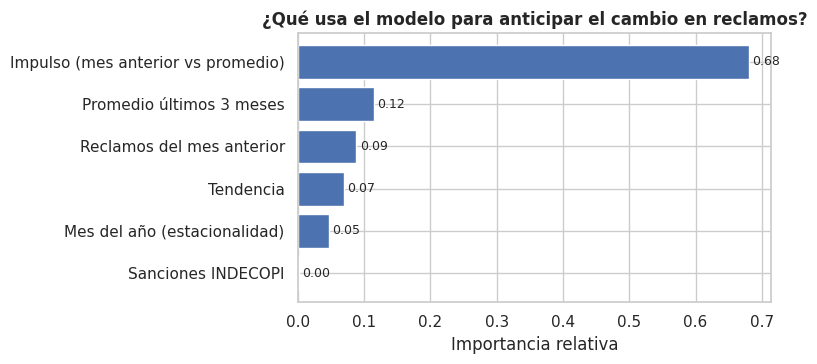

In [37]:
# ============================================================
# MODELO 2 - Importancia de variables
# ============================================================
imp = pd.Series(modelos['RF con INDECOPI'].feature_importances_, index=feat_enriq).sort_values()
nombres = {'lag1': 'Reclamos del mes anterior', 'media3': 'Promedio últimos 3 meses',
           'impulso': 'Impulso (mes anterior vs promedio)', 'mes_del_año': 'Mes del año (estacionalidad)',
           't': 'Tendencia', 'log_sanciones': 'Sanciones INDECOPI'}
plt.figure(figsize=(8, 3.8))
plt.barh([nombres[i] for i in imp.index], imp.values, color='#4C72B0')
for i, v in enumerate(imp.values):
    plt.text(v + 0.005, i, f'{v:.2f}', va='center', fontsize=9)
plt.title('¿Qué usa el modelo para anticipar el cambio en reclamos?', fontweight='bold')
plt.xlabel('Importancia relativa')
plt.tight_layout(); plt.show()

**Interpretación.**

El gráfico muestra en qué se fija el Random Forest para anticipar cómo cambiarán los reclamos de una operadora el mes siguiente. Casi todo el peso lo tiene el **impulso reciente (68%)**: si el último mes estuvo por encima o por debajo del promedio de los tres anteriores. Mucho más atrás quedan el promedio de los últimos 3 meses (12%), los reclamos del mes anterior (9%), la tendencia (7%) y el mes del año (5%).

Las sanciones de INDECOPI no aportan nada porque es un dato fijo por operadora, que no cambia de un mes a otro, así que no pueden explicar por qué los reclamos suben o bajan. Eso no les quita valor: sirven para otra pregunta, la de identificar qué operadoras son más riesgosas (regresión y gráfico 7), no para pronosticar el mes siguiente.

Que lo que mejor anticipa los reclamos del próximo mes es lo que venía pasando en los meses recientes. Basta con seguir la variación mensual de cada operadora para detectar a tiempo a las que empiezan a subir.

In [49]:
# ============================================================
# CLUSTERING - Paso 1: Firma de reclamo por empresa
# ============================================================
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

df_cl = df_merged.copy()
top_mat_cl = df_cl.groupby('materia_principal')[COL_REC].sum().nlargest(8).index
df_cl['materia_grp'] = np.where(df_cl['materia_principal'].isin(top_mat_cl),
                                df_cl['materia_principal'], 'Otras materias reclamables')

CORTO = {'Facturación y cobro': 'Facturación',
         'Calidad e idoneidad en la prestación del servicio': 'Calidad del servicio',
         'Incumplimiento de condiciones contractuales, ofertas y promociones': 'Incumpl. de contrato',
         'Contratación no solicitada': 'Contrat. no solicitada',
         'Falta de ejecución de baja o suspensión del servicio': 'No ejecutan la baja',
         'Falta de servicio': 'Falta de servicio', 'Migración': 'Migración',
         'Otras materias reclamables': 'Otras'}

firma = df_cl.pivot_table(index='empresa_norm', columns='materia_grp', values=COL_REC, aggfunc='sum', fill_value=0)
firma_pct = (firma.div(firma.sum(axis=1), axis=0) * 100).rename(columns=lambda c: CORTO.get(c, c))

MIN_RECLAMOS = 1000          # % estables solo con volumen suficiente
emp_cl = df_empresa.query('reclamos_totales >= @MIN_RECLAMOS').set_index('empresa_norm')
X_cl = firma_pct.loc[emp_cl.index].copy()
X_cl['Tamaño (log reclamos)']     = np.log1p(emp_cl['reclamos_totales'])
X_cl['Sanciones (log, INDECOPI)'] = np.log1p(emp_cl['total_sanciones'].fillna(0))
X_scaled = StandardScaler().fit_transform(X_cl)

print(f"Empresas para clustering: {len(X_cl)} de {len(df_empresa)} (≥ {MIN_RECLAMOS:,} reclamos)")
print(f"Concentran el {emp_cl['reclamos_totales'].sum() / total_reclamos * 100:.1f}% de los reclamos")

Empresas para clustering: 22 de 82 (≥ 1,000 reclamos)
Concentran el 99.8% de los reclamos


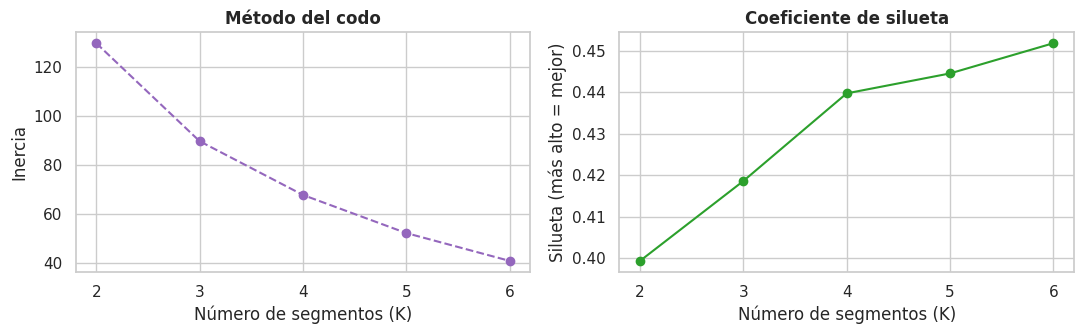

,K,Silueta
0,2,0.399
1,3,0.419
2,4,0.440
3,5,0.445
4,6,0.452


In [39]:
# ============================================================
# CLUSTERING - Paso 2: ¿Cuántos segmentos? Codo + silueta
# ============================================================
rango_k = range(2, 7)
inercias, siluetas = [], []
for k in rango_k:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=20).fit(X_scaled)
    inercias.append(km.inertia_); siluetas.append(silhouette_score(X_scaled, km.labels_))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(list(rango_k), inercias, 'o--', color='#9467bd'); ax[0].set_title('Método del codo', fontweight='bold')
ax[0].set_xlabel('Número de segmentos (K)'); ax[0].set_ylabel('Inercia')
ax[1].plot(list(rango_k), siluetas, 'o-', color='#2ca02c'); ax[1].set_title('Coeficiente de silueta', fontweight='bold')
ax[1].set_xlabel('Número de segmentos (K)'); ax[1].set_ylabel('Silueta (más alto = mejor)')
ax[0].set_xticks(list(rango_k)); ax[1].set_xticks(list(rango_k))
plt.tight_layout(); plt.show()

display(pd.DataFrame({'K': list(rango_k), 'Silueta': np.round(siluetas, 3)}))

**Interpretación.** Para decidir en cuántos grupos dividir a las operadoras usamos dos criterios. El método del codo mide qué tan parecidas son entre sí las operadoras de un mismo grupo: la mayor mejora ocurre al pasar de 2 a 3 grupos y, a partir de 4, cada grupo adicional aporta cada vez menos. La silueta mide qué tan bien separados quedan los grupos (más alto es mejor): sube de 0.399 con 2 grupos a 0.452 con 6.

Por silueta, 6 grupos sería la mejor opción, pero deja un "grupo" formado por una sola empresa, que no es un segmento sino un caso aislado. Por eso **elegimos K = 5** (silueta 0.445): es casi igual de bueno, todos sus grupos tienen al menos 2 operadoras y cada uno se puede describir con criterio de negocio.

Un valor de 0.445 indica grupos razonablemente diferenciados, aunque no perfectamente separados. Con solo 22 operadoras, la segmentación debe leerse como una guía para ordenar la supervisión, no como una clasificación definitiva.

In [40]:
# ============================================================
# CLUSTERING - Paso 3a: Elección de K y segmentos finales
# ============================================================
# Regla: mejor silueta SIN segmentos de 1 sola empresa
eleccion = []
for k in range(2, 7):
    lab = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=20).fit_predict(X_scaled)
    tam = np.bincount(lab)
    eleccion.append({'K': k, 'Silueta': round(silhouette_score(X_scaled, lab), 3),
                     'Tamaños': sorted(tam.tolist(), reverse=True), 'Mínimo': tam.min()})
eleccion = pd.DataFrame(eleccion)
display(eleccion)

validos = eleccion[eleccion['Mínimo'] >= 2]
K_FINAL = int(validos.loc[validos['Silueta'].idxmax(), 'K']) if not validos.empty else 3
print(f"K elegido: {K_FINAL} (mejor silueta sin segmentos de una sola empresa)\n")

km_final = KMeans(n_clusters=K_FINAL, random_state=RANDOM_STATE, n_init=20).fit(X_scaled)
X_cl['Segmento'] = km_final.labels_

cols_materia = list(firma_pct.columns)
perfil = X_cl.groupby('Segmento')[cols_materia].mean().round(1)

resumen_seg = (emp_cl.assign(Segmento=X_cl['Segmento'])
               .groupby('Segmento')
               .agg(n_empresas=('reclamos_totales', 'size'),
                    reclamos=('reclamos_totales', 'sum'),
                    sanciones=('total_sanciones', 'sum'),
                    empresas=('reclamos_totales', lambda s: ', '.join(s.sort_values(ascending=False).index[:6]))))
resumen_seg['% reclamos del mercado'] = (resumen_seg['reclamos'] / total_reclamos * 100).round(1)
resumen_seg['sanciones x 100k'] = (resumen_seg['sanciones'] / resumen_seg['reclamos'] * 1e5).round(1)
print("Resumen de segmentos:")
display(resumen_seg)

,K,Silueta,Tamaños,Mínimo
0,2,0.399,"[13, 9]",9
1,3,0.419,"[11, 8, 3]",3
2,4,0.440,"[11, 6, 3, 2]",2
3,5,0.445,"[11, 4, 3, 2, 2]",2
4,6,0.452,"[11, 4, 2, 2, 2, 1]",1


K elegido: 5 (mejor silueta sin segmentos de una sola empresa)

Resumen de segmentos:


,n_empresas,reclamos,sanciones,empresas,% reclamos del mercado,sanciones x 100k
Segmento,,,,,,
0,11,57679.0,0.0,"TELECOMUNICACIONES ARGONZA, TV NOR COMUNICACIO...",1.4,0.0
1,4,1118327.0,63.0,"AMERICA MOVIL, VIETTEL, WOW TEL, DIRECTV",26.7,5.6
2,2,2940652.0,385.0,"INTEGRATEL, ENTEL",70.1,13.1
3,2,2682.0,0.0,"GILAT NETWORKS, P Y D TELECOM",0.1,0.0
4,3,66624.0,1.0,"WI NET TELECOM, FIBERLINE, HUGHES DE",1.6,1.5


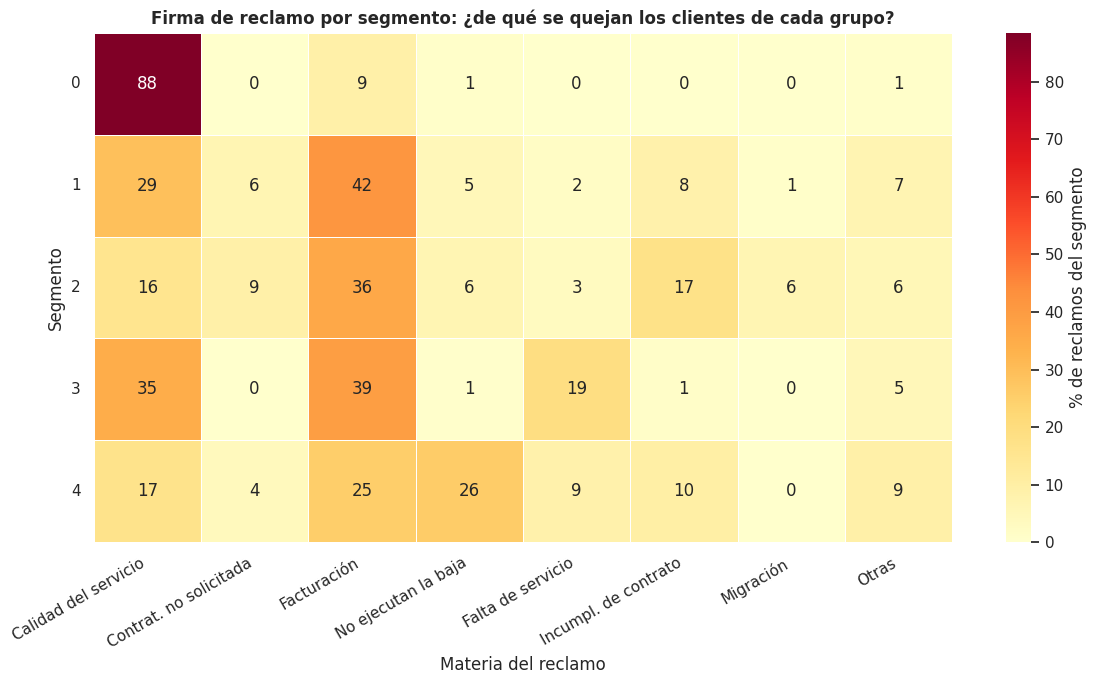

In [41]:
# ============================================================
# CLUSTERING - Paso 3b: Firma de reclamo por segmento (heatmap)
# ============================================================
plt.figure(figsize=(12, 0.9 * K_FINAL + 2.5))
sns.heatmap(perfil, annot=True, fmt='.0f', cmap='YlOrRd', linewidths=.5,
            cbar_kws={'label': '% de reclamos del segmento'})
plt.title('Firma de reclamo por segmento: ¿de qué se quejan los clientes de cada grupo?', fontweight='bold')
plt.xlabel('Materia del reclamo'); plt.ylabel('Segmento')
plt.xticks(rotation=30, ha='right'); plt.yticks(rotation=0)
plt.tight_layout(); plt.show()

**Interpretación.** Cada fila es un segmento y cada casilla indica qué porcentaje de sus reclamos corresponde a esa materia. Cada grupo tiene un patrón propio:

- **Segmento Regionales:** casi todo es **calidad del servicio (88%)**. Es un problema técnico.
- **Segmento Masivo:** manda la **facturación (42%)**, seguida de la calidad del servicio (29%).
- **Segmento en base a Integratel y Entel:** reclamos comerciales: **facturación (36%)**, incumplimiento de contrato (17%) y contratación no solicitada (9%).
- **Segmento 3 (nicho):** facturación (39%) y calidad (35%), y es el único donde pesa la **falta de servicio (19%)**.
- **Segmento 4:** el único donde **no ejecutar la baja (26%)** pesa tanto como la facturación (25%).

NO todas las operadoras tienen el mismo problema: en las grandes el reclamo es comercial (cobros y contratos) y en las regionales es técnico. La supervisión debe enfocarse distinto según el segmento.

In [42]:
# ============================================================
# CLUSTERING - Paso 4: Nombres de negocio de cada segmento
# ============================================================
# Se nombra cada segmento según la empresa que lo identifica (robusto si cambia la numeración)
REGLAS_NOMBRE = [
    ('INTEGRATEL',     'Líderes con alto riesgo regulatorio'),
    ('AMERICA MOVIL',  'Masivas con conflictos de facturación'),
    ('WI NET TELECOM', 'Proveedores con problemas para dar de baja'),
    ('GILAT NETWORKS', 'Nicho con interrupciones de servicio'),
]
NOMBRES_SEGMENTO = {}
for empresa, nombre in REGLAS_NOMBRE:
    if empresa in X_cl.index:
        NOMBRES_SEGMENTO.setdefault(X_cl.loc[empresa, 'Segmento'], nombre)
for seg in sorted(X_cl['Segmento'].unique()):
    NOMBRES_SEGMENTO.setdefault(seg, 'Regionales con fallas de calidad')

X_cl['Nombre segmento'] = X_cl['Segmento'].map(NOMBRES_SEGMENTO)
df_empresa['segmento'] = df_empresa['empresa_norm'].map(X_cl['Nombre segmento'])
resumen_seg.index = resumen_seg.index.map(NOMBRES_SEGMENTO)

display(resumen_seg[['n_empresas', 'empresas', '% reclamos del mercado', 'sanciones x 100k']])

,n_empresas,empresas,% reclamos del mercado,sanciones x 100k
Segmento,,,,
Regionales con fallas de calidad,11,"TELECOMUNICACIONES ARGONZA, TV NOR COMUNICACIO...",1.4,0.0
Masivas con conflictos de facturación,4,"AMERICA MOVIL, VIETTEL, WOW TEL, DIRECTV",26.7,5.6
Líderes con alto riesgo regulatorio,2,"INTEGRATEL, ENTEL",70.1,13.1
Nicho con interrupciones de servicio,2,"GILAT NETWORKS, P Y D TELECOM",0.1,0.0
Proveedores con problemas para dar de baja,3,"WI NET TELECOM, FIBERLINE, HUGHES DE",1.6,1.5


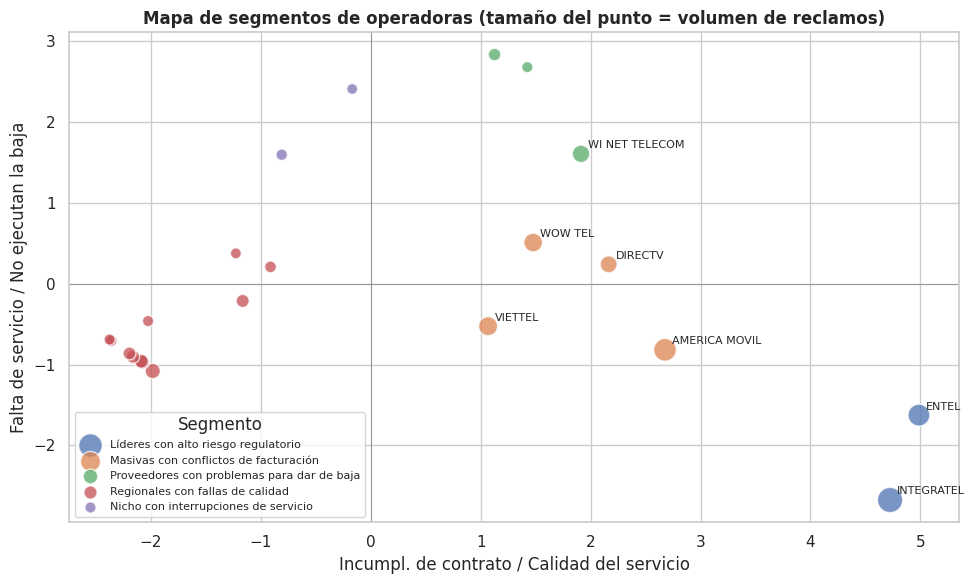

,Eje,Qué representa,% de la variación que resume
0,Horizontal,Incumpl. de contrato / Calidad del servicio,51
1,Vertical,Falta de servicio / No ejecutan la baja,20


In [43]:
# ============================================================
# CLUSTERING - Paso 5: Mapa de segmentos
# ============================================================
from sklearn.decomposition import PCA
reductor = PCA(n_components=2, random_state=RANDOM_STATE)
coords = reductor.fit_transform(X_scaled)
eje_x, eje_y = coords[:, 0], coords[:, 1]

variables = X_cl.columns[:X_scaled.shape[1]]
pesos = pd.DataFrame(reductor.components_.T, index=variables, columns=['Eje horizontal', 'Eje vertical'])
nombre_eje = lambda c: ' / '.join(pesos[c].abs().nlargest(2).index)

fig, ax = plt.subplots(figsize=(10, 6))
tam_pts = 30 + 300 * (X_cl['Tamaño (log reclamos)'] / X_cl['Tamaño (log reclamos)'].max()) ** 3
for seg in X_cl['Nombre segmento'].unique():
    m = (X_cl['Nombre segmento'] == seg).values
    ax.scatter(eje_x[m], eje_y[m], s=tam_pts[m], label=seg, alpha=0.75, edgecolor='white')
for i, emp in enumerate(X_cl.index):
    if np.expm1(X_cl['Tamaño (log reclamos)'].iloc[i]) > 40000:
        ax.annotate(emp, (eje_x[i], eje_y[i]), fontsize=8, xytext=(5, 4), textcoords='offset points')
ax.axhline(0, color='grey', lw=0.5); ax.axvline(0, color='grey', lw=0.5)
ax.set_xlabel(nombre_eje('Eje horizontal')); ax.set_ylabel(nombre_eje('Eje vertical'))
ax.set_title('Mapa de segmentos de operadoras (tamaño del punto = volumen de reclamos)', fontweight='bold')
ax.legend(title='Segmento', fontsize=8); plt.tight_layout(); plt.show()

lectura_ejes = pd.DataFrame({
    'Eje': ['Horizontal', 'Vertical'],
    'Qué representa': [nombre_eje('Eje horizontal'), nombre_eje('Eje vertical')],
    '% de la variación que resume': (reductor.explained_variance_ratio_ * 100).round(0).astype(int)})
display(lectura_ejes)

**Interpretación.** El mapa ubica a las 22 operadoras según su perfil de reclamos: las que están cerca se parecen entre sí. Los dos ejes resumen el 71% de las diferencias entre ellas. Hacia la **derecha** están las operadoras con reclamos comerciales (como el incumplimiento de contrato) y hacia la **izquierda** las que tienen reclamos por calidad del servicio; hacia **arriba**, aquellas donde pesan la falta de servicio y las bajas no ejecutadas.

- **Líderes con alto riesgo regulatorio (Integratel, Entel):** quedan solas en el extremo derecho, lejos de todas las demás. Concentran el 70.1% de los reclamos del mercado y tienen 13.1 sanciones por cada 100 mil reclamos, el nivel más alto.
- **Masivas con conflictos de facturación (América Móvil, Viettel, WOW Tel, DirecTV):** al centro-derecha, con el 26.7% de los reclamos y 5.6 sanciones por 100 mil.
- **Regionales con fallas de calidad (11 operadoras):** agrupadas a la izquierda, con solo 1.4% de los reclamos y ninguna sanción.
- **Proveedores con problemas para dar de baja y Nicho con interrupciones de servicio:** arriba, con menos del 2% de los reclamos entre los dos.

Integratel y Entel no solo son las más grandes: tienen un perfil de reclamos distinto al del resto del mercado y el mayor nivel de sanciones. Ese es el segmento donde la supervisión rinde más.

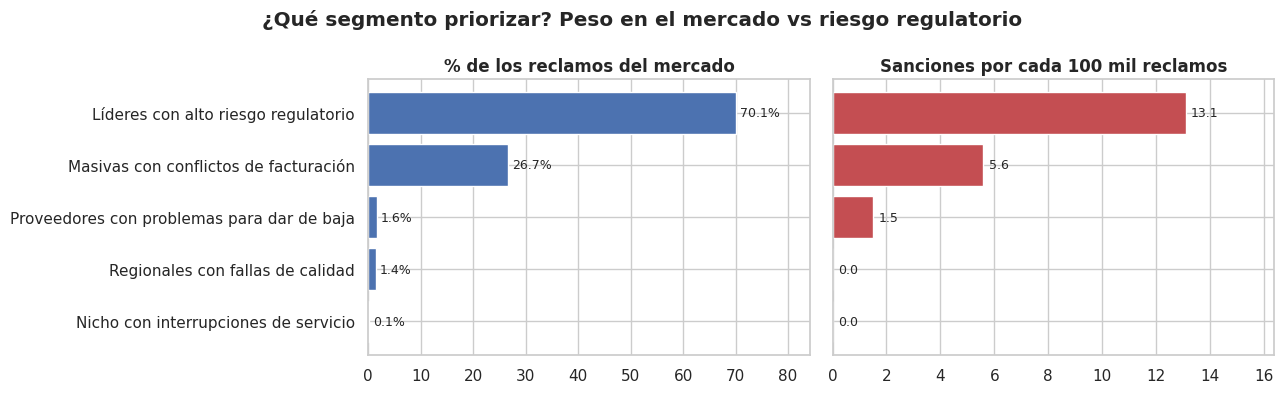

In [44]:
# ============================================================
# CLUSTERING - Paso 6: ¿Qué segmento priorizar? Peso vs riesgo
# ============================================================
seg_plot = resumen_seg.sort_values('% reclamos del mercado')

fig, ax = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
ax[0].barh(seg_plot.index, seg_plot['% reclamos del mercado'], color='#4C72B0')
for i, v in enumerate(seg_plot['% reclamos del mercado']):
    ax[0].text(v + 0.8, i, f'{v:.1f}%', va='center', fontsize=9)
ax[0].set_title('% de los reclamos del mercado', fontweight='bold')
ax[0].set_xlim(0, seg_plot['% reclamos del mercado'].max() * 1.2)

ax[1].barh(seg_plot.index, seg_plot['sanciones x 100k'], color='#C44E52')
for i, v in enumerate(seg_plot['sanciones x 100k']):
    ax[1].text(v + 0.2, i, f'{v:.1f}', va='center', fontsize=9)
ax[1].set_title('Sanciones por cada 100 mil reclamos', fontweight='bold')
ax[1].set_xlim(0, seg_plot['sanciones x 100k'].max() * 1.25)

plt.suptitle('¿Qué segmento priorizar? Peso en el mercado vs riesgo regulatorio', fontweight='bold')
plt.tight_layout(); plt.show()

**Interpretación.** El gráfico compara dos cosas por segmento: cuánto pesa en el mercado (izquierda) y cuántas sanciones acumula por cada 100 mil reclamos (derecha). El segmento de **Líderes** (Integratel y Entel) encabeza ambas: tiene el 70.1% de los reclamos y más del doble de sanciones por reclamo que las **Masivas** (13.1 frente a 5.6). Los otros tres segmentos juntos suman apenas el 3.1% de los reclamos y casi no tienen sanciones.

El segmento más grande es también el más riesgoso, así que la prioridad de supervisión es clara: Integratel y Entel, y en particular sus procesos comerciales (facturación, ofertas y contrataciones). Las regionales necesitan otra intervención: verificar la calidad técnica del servicio, no la facturación.

#Enriquecimiento con encuesta propia


In [45]:
# ============================================================
# Limpieza de la encuesta + bitácora
# ============================================================
enc = (encuesta_raw if 'encuesta_raw' in globals() else encuesta).copy()

col = lambda patron: next(c for c in enc.columns if re.search(patron, str(c), re.I))
C_ACEPTA, C_OPER = col('Aceptas'), col(r'empresa operadora')
C_SERV, C_DEP    = col(r'tipo de servicio'), col(r'departamento')
C_RECL, C_MOT    = col(r'presentado un reclamo'), col(r'motivo principal')
C_CONT, C_FACIL  = col(r'Cuántas veces'), col(r'qué tan fácil')
C_CAMBIO         = col(r'cambies de operador')

def sin_tildes(x):
    '''Minúsculas, sin tildes, sin emojis ni signos: deja solo letras y espacios.'''
    if pd.isna(x): return ''
    s = ''.join(c for c in unicodedata.normalize('NFKD', str(x)) if not unicodedata.combining(c)).lower()
    return re.sub(r'[^a-z0-9 ]', ' ', s).strip()

# 1. Diagnóstico: ¿cómo está escrita la respuesta de consentimiento?
print("Respuestas a '¿Aceptas participar?' (texto original):")
display(enc[C_ACEPTA].value_counts(dropna=False).to_frame('n'))

# 2. Consentimiento informado: solo se conservan los que aceptaron explícitamente
acepta = enc[C_ACEPTA].map(sin_tildes)
dijo_si    = (acepta.str.startswith('si') | acepta.str.contains('acepto')) & ~acepta.str.startswith('no')
dijo_no    = acepta.str.startswith('no')
en_blanco  = acepta.eq('')

n0 = len(enc)
enc = enc[dijo_si]
n_consent = len(enc)

# 3. Operadora obligatoria
enc = enc[enc[C_OPER].map(sin_tildes).ne('')]
n_validas = len(enc)

# 4. Operadora -> nombre normalizado de OSIPTEL
def mapear_operadora(x):
    s = sin_tildes(x)
    reglas = [(('movistar', 'telefonica', 'integratel'), 'INTEGRATEL'), (('claro', 'america movil'), 'AMERICA MOVIL'),
              (('entel',), 'ENTEL'), (('bitel', 'viettel'), 'VIETTEL'), (('wow',), 'WOW TEL'),
              (('win',), 'WI NET TELECOM'), (('directv',), 'DIRECTV')]
    for claves, destino in reglas:
        if any(k in s for k in claves):
            return destino
    return 'OTRA'

# 5. Escalas -> número del 1 al 5
LIKERT = {'nada': 1, 'muy dificil': 1, 'muy improbable': 1, 'poco': 2, 'dificil': 2, 'improbable': 2,
          'neutral': 3, 'ni ': 3, 'regular': 3, 'facil': 4, 'probable': 4, 'muy facil': 5, 'muy probable': 5}
def a_likert(x):
    if pd.isna(x): return np.nan
    try: return float(x)
    except (TypeError, ValueError):
        s = sin_tildes(x) + ' '
        for k in sorted(LIKERT, key=len, reverse=True):
            if k in s: return LIKERT[k]
    return np.nan

enc['empresa_norm'] = enc[C_OPER].map(mapear_operadora)
enc['reclamo']      = enc[C_RECL].map(sin_tildes).str.startswith('si').astype(int)
enc['facilidad']    = enc[C_FACIL].map(a_likert)
enc['prob_cambio']  = enc[C_CAMBIO].map(a_likert)

# 6. Bitácora
print("\nBITÁCORA - ENCUESTA")
print(f"  Respuestas recibidas                : {n0}")
print(f"  Descartadas - respondió 'No'        : {int(dijo_no.sum())}")
print(f"  Descartadas - consentimiento vacío  : {int(en_blanco.sum())}")
print(f"  Descartadas - otro texto            : {n0 - n_consent - int(dijo_no.sum()) - int(en_blanco.sum())}")
print(f"  Descartadas - sin operadora         : {n_consent - n_validas}")
print(f"  Respuestas válidas                  : {n_validas}  (mínimo del curso: 60)")
print(f"  Escalas leídas como número          : facilidad {enc['facilidad'].notna().sum()} | cambio {enc['prob_cambio'].notna().sum()}")
display(enc['empresa_norm'].value_counts().to_frame('respuestas'))

Respuestas a '¿Aceptas participar?' (texto original):


,n
¿Aceptas participar? 🙋🏻‍♀️,
NaN,40
"Sí, acepto participar",19



BITÁCORA - ENCUESTA
  Respuestas recibidas                : 59
  Descartadas - respondió 'No'        : 0
  Descartadas - consentimiento vacío  : 40
  Descartadas - otro texto            : 0
  Descartadas - sin operadora         : 0
  Respuestas válidas                  : 19  (mínimo del curso: 60)
  Escalas leídas como número          : facilidad 16 | cambio 18


,respuestas
empresa_norm,
INTEGRATEL,7
ENTEL,6
AMERICA MOVIL,3
OTRA,2
VIETTEL,1


Tasa de cruce encuesta -> OSIPTEL: 100% de las operadoras reportadas


,respuestas,pct_reclamo,facilidad_media,prob_cambio_media,reclamos_totales,total_sanciones,sanciones_x_100k
empresa_norm,,,,,,,
ENTEL,6,50.00,3.00,2.50,543391.0,192.0,35.333673
INTEGRATEL,7,71.43,3.57,2.43,2397261.0,193.0,8.050855


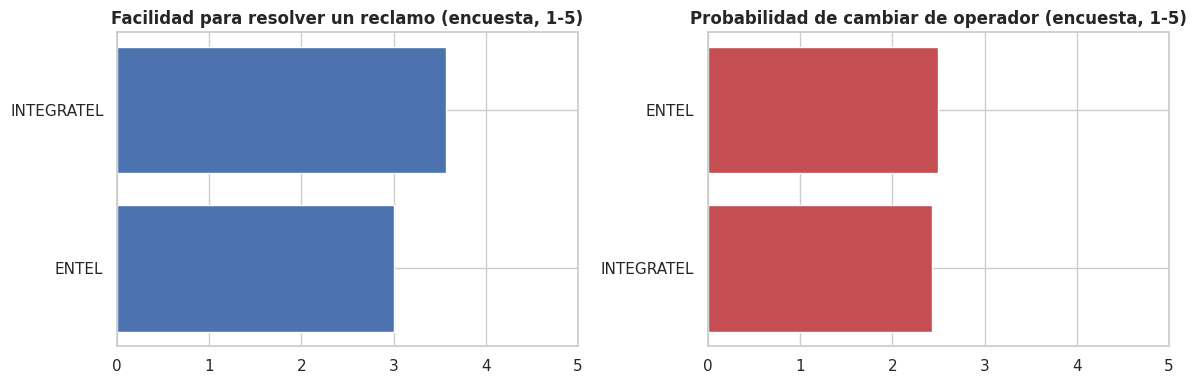

In [46]:
# ============================================================
# Encuesta × OSIPTEL × INDECOPI: experiencia declarada vs riesgo observado
# ============================================================
exp = (enc.groupby('empresa_norm')
          .agg(respuestas=('reclamo', 'size'),
               pct_reclamo=('reclamo', lambda s: s.mean() * 100),
               facilidad_media=('facilidad', 'mean'),
               prob_cambio_media=('prob_cambio', 'mean'))
          .query('respuestas >= 5')                       # mínimo para reportar por operadora
          .round(2))
cruce_enc = exp.join(df_empresa.set_index('empresa_norm')[['reclamos_totales', 'total_sanciones', 'sanciones_x_100k']])
cruce_enc['tasa_cruce'] = cruce_enc['reclamos_totales'].notna()
print(f"Tasa de cruce encuesta -> OSIPTEL: {cruce_enc['tasa_cruce'].mean() * 100:.0f}% de las operadoras reportadas")
display(cruce_enc.drop(columns='tasa_cruce'))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
d = cruce_enc.sort_values('facilidad_media')
ax[0].barh(d.index, d['facilidad_media'], color='#4C72B0')
ax[0].set_title('Facilidad para resolver un reclamo (encuesta, 1-5)', fontweight='bold'); ax[0].set_xlim(0, 5)
d = cruce_enc.sort_values('prob_cambio_media')
ax[1].barh(d.index, d['prob_cambio_media'], color='#C44E52')
ax[1].set_title('Probabilidad de cambiar de operador (encuesta, 1-5)', fontweight='bold'); ax[1].set_xlim(0, 5)
plt.tight_layout(); plt.show()

**Interpretación.** El gráfico compara lo que respondieron los usuarios de las dos operadoras con suficientes encuestas. Los de **Entel** califican la resolución de sus reclamos como algo más difícil (**3.0 de 5**) que los de **Integratel (3.57)**. La intención de cambiar de operador es baja y casi igual en ambas (≈ 2.5 de 5).

La diferencia va en la misma dirección que el cruce OSIPTEL × INDECOPI, donde Entel tiene 35 sanciones por cada 100 mil reclamos frente a 8 de Integratel. Sin embargo, con tan pocas respuestas no se puede afirmar que la encuesta lo confirme.

*Limitación:* la encuesta tiene 19 respuestas válidas (el mínimo del curso es 60) y solo 6–7 por operadora. Es una señal que acompaña al análisis principal, no una prueba, y no permite comparar a las demás operadoras.

**¿Qué significa para OSIPTEL?** Que la experiencia del usuario apunta al mismo foco que los datos, pero para usarla como evidencia haría falta una encuesta más grande.

#Impacto del enriquecimiento: conclusiones con vs sin cruce

In [47]:
# ============================================================
# Impacto del enriquecimiento: ¿qué conclusiones cambian con el cruce?
# ============================================================
pd.set_option('display.max_colwidth', None)

# Cobertura del cruce antes / después de corregir el alias Integratel
emp_cruzadas = set(df_empresa.dropna(subset=['total_sanciones'])['empresa_norm'])
cob = lambda emps: df_empresa.loc[df_empresa['empresa_norm'].isin(emps), 'reclamos_totales'].sum() / total_reclamos * 100
cob_antes, cob_despues = cob(emp_cruzadas - {'INTEGRATEL'}), cob(emp_cruzadas)

rk_vol    = df_empresa.nlargest(3, 'reclamos_totales')['empresa_norm'].tolist()
rk_riesgo = (df_empresa.dropna(subset=['total_sanciones']).query('reclamos_totales >= 10000')
             .nlargest(3, 'sanciones_x_100k')['empresa_norm'].tolist())
wape = tabla_modelos.set_index('Modelo')['Error % ponderado (WAPE)']
sanc_integratel = df_empresa.loc[df_empresa['empresa_norm'] == 'INTEGRATEL', 'total_sanciones'].iloc[0]

# Encuesta: se lee de la tabla calculada (no se escribe el número a mano)
fac = cruce_enc['facilidad_media'].dropna().sort_values()
if len(fac) >= 2:
    txt_encuesta = (f"{fac.index[0].title()}: resolución más difícil "
                    f"({fac.iloc[0]:.2f} vs {fac.iloc[-1]:.2f} de {fac.index[-1].title()}; n = {len(enc)} respuestas)")
else:
    txt_encuesta = f"Muestra insuficiente para comparar operadoras (n = {len(enc)} respuestas)"

impacto = pd.DataFrame([
    ["Cobertura del cruce (% de reclamos con dato de sanción)", f"{cob_antes:.1f}%", f"{cob_despues:.1f}%"],
    ["Sanciones de la operadora con más reclamos (Integratel)", "Sin registro (0)", f"{sanc_integratel:.0f} sanciones"],
    ["Pregunta huérfana: ¿más reclamos = más sanciones?", "No se puede responder",
     "Sí en volumen, pero las sanciones por reclamo varían 4-5 veces entre operadoras"],
    ["¿A qué operadoras priorizar?", f"Por volumen: {', '.join(rk_vol)}",
     f"Por sanciones por reclamo: {', '.join(rk_riesgo)}"],
    ["Error del pronóstico mensual (WAPE)", f"{wape['RF sin INDECOPI']:.1f}%",
     f"{wape['RF con INDECOPI']:.1f}% (no mejora; método ingenuo: {wape['Ingenuo (= mes anterior)']:.1f}%)"],
    ["Asociación entre sanciones y reclamos (regresión)", "No medible",
     f"El doble de sanciones se asocia con {(2**b_sanc - 1)*100:+.0f}% reclamos mensuales (no causal)"],
    ["Experiencia del usuario (encuesta)", "No disponible", txt_encuesta],
], columns=['Conclusión', 'Sin enriquecimiento', 'Con enriquecimiento'])

display(impacto.style.set_properties(**{'text-align': 'left'}).hide(axis='index'))

Conclusión,Sin enriquecimiento,Con enriquecimiento
Cobertura del cruce (% de reclamos con dato de sanción),38.2%,95.3%
Sanciones de la operadora con más reclamos (Integratel),Sin registro (0),193 sanciones
Pregunta huérfana: ¿más reclamos = más sanciones?,No se puede responder,"Sí en volumen, pero las sanciones por reclamo varían 4-5 veces entre operadoras"
¿A qué operadoras priorizar?,"Por volumen: INTEGRATEL, AMERICA MOVIL, ENTEL","Por sanciones por reclamo: ENTEL, INTEGRATEL, AMERICA MOVIL"
Error del pronóstico mensual (WAPE),13.5%,13.5% (no mejora; método ingenuo: 11.8%)
Asociación entre sanciones y reclamos (regresión),No medible,El doble de sanciones se asocia con +149% reclamos mensuales (no causal)
Experiencia del usuario (encuesta),No disponible,Entel: resolución más difícil (3.00 vs 3.57 de Integratel; n = 19 respuestas)


**Conclusión: cruzar las fuentes cambió lo que habríamos concluido.**

Si nos hubiéramos quedado solo con los datos de OSIPTEL, este análisis habría llegado a conclusiones distintas, y en un caso, equivocadas. Esto es lo que aportó el enriquecimiento:

- **Nos evitó un error de fondo.** Telefónica cambió de nombre a Integratel, y cada fuente la registra distinto. Sin corregir eso, la operadora con más reclamos del país aparecía sin ninguna sanción, y habríamos concluido que *"el volumen de reclamos no predice el riesgo regulatorio"*. Al corregirlo, Integratel resulta ser la más sancionada (193 sanciones) y el cruce pasa de cubrir el 38.2% de los reclamos a cubrir el 95.3%.
- **Cambió a quién hay que mirar primero.** Por volumen, el orden es Integratel, América Móvil, Entel. Pero al sumar las sanciones, **Entel pasa al primer lugar**: acumula entre 4 y 5 veces más sanciones por reclamo que las otras dos grandes.
- **Nos mostró para qué sirven las sanciones y para qué no.** No ayudan a pronosticar el mes siguiente (el error es 13.5% con o sin ellas, frente a 11.8% del método más simple). Sí ayudan a distinguir qué operadoras concentran reclamos y riesgo: el doble de sanciones se asocia con 149% más reclamos mensuales. Es una asociación, no una causa.
- **La encuesta va en la misma dirección, con cautela.** Los usuarios de Entel califican la resolución de sus reclamos como más difícil (3.00 de 5) que los de Integratel (3.57). Con 19 respuestas válidas es una señal, no una prueba.

**Respuesta a la pregunta huérfana:**
Sí, las operadoras con más reclamos son también las más sancionadas, pero no en la misma proporción. El riesgo regulatorio no depende solo de cuántos reclamos recibe una operadora, sino también de cuántas sanciones acumula por cada uno. Eso ninguna de las dos fuentes lo muestra por separado: solo se ve al cruzarlas.

# Recomendaciones y business case

**Cliente:** área de supervisión de OSIPTEL. **Decisión que debe tomar:** a qué operadoras, en qué temas y en qué meses concentrar su capacidad de fiscalización en 2026.

## Recomendaciones

**1. Priorizar la supervisión por sanciones por reclamo, no por volumen.** Entel pasa al primer lugar del plan de supervisión, seguido de Integratel.
- *Hallazgo que la sustenta:* Entel tiene 35 sanciones por cada 100 mil reclamos, frente a 8 de Integratel y 7 de América Móvil (gráfico 7). Por volumen, Entel sería recién la tercera.
- *Indicador de seguimiento:* sanciones por 100 mil reclamos, por operadora, cada semestre.

**2. Abrir una supervisión temática de facturación y cobro en servicios móviles, a nivel nacional.**
- *Hallazgo que la sustenta:* esa sola combinación es el 34.1% de los reclamos del país, y pesa igual o más fuera de Lima (índice regiones/Lima de 1.09).
- *Indicador de seguimiento:* % de reclamos por facturación móvil sobre el total.

**3. Programar la supervisión con el calendario de reclamos:** preparar acciones en abril–junio y exigir a las operadoras planes de atención antes de agosto y enero.
- *Hallazgo que la sustenta:* agosto (+9%) y enero (+6%) son los picos estacionales; el pronóstico de 2026 va de 89 a 111 mil reclamos mensuales, con máximos en esos dos meses.
- *Indicador de seguimiento:* reclamos mensuales reales frente al pronóstico.

**4. Activar una alerta temprana para las operadoras con tendencia creciente:** hoy, Entel y Viettel (Bitel).
- *Hallazgo que la sustenta:* Entel pasó de ~12 mil a ~20 mil reclamos mensuales, y Viettel multiplicó por 5 los suyos, mientras el mercado bajaba (gráfico 5).
- *Indicador de seguimiento:* variación de reclamos frente al mes anterior y al mismo mes del año anterior.

**5. Diferenciar la supervisión por segmento:** procesos comerciales en las grandes, calidad técnica en las regionales.
- *Hallazgo que la sustenta:* en las 11 operadoras regionales, el 88% de los reclamos es por calidad del servicio; en Integratel y Entel dominan facturación, contratos y contrataciones no solicitadas (clustering).
- *Indicador de seguimiento:* composición de reclamos por materia en cada segmento.

**Sobre el modelo predictivo:** para la alerta de la recomendación 4 se recomienda la regla simple (comparar con el mes anterior y con la estacionalidad) y **no** el Random Forest, porque en 2025 el método ingenuo tuvo menor error (11.8% frente a 13.5%).

## Business case

- **Dónde está el problema.** Dos operadoras (Integratel y Entel) concentran el 70.1% de los reclamos y 385 de las sanciones del ranking. Concentrar la supervisión en ellas cubre 7 de cada 10 reclamos del mercado sin ampliar el número de empresas fiscalizadas.
- **Tamaño de la oportunidad.** La facturación y cobro en móviles suma alrededor de 1.43 millones de reclamos en tres años, cerca de 477 mil por año. Como escenario, una reducción del 10% en esa sola combinación equivale a unos 48 mil reclamos menos al año.
- **Es alcanzable.** América Móvil redujo sus reclamos mensuales en alrededor de 85% entre mediados de 2023 y fines de 2024, lo que muestra que una caída sostenida es posible dentro del mismo mercado.
- **Exposición sancionadora.** Las operadoras cruzadas acumulan cerca de 487 UIT en multas de INDECOPI, unos S/ 2.6 millones a valor UIT 2025; Integratel sola representa S/ 1.75 millones.
- **Costo de no actuar.** El pronóstico para 2026 es de aproximadamente 1.2 millones de reclamos, similar a 2025: sin intervención no se prevé una mejora natural.

## Limitaciones

- El ranking de INDECOPI cubre 48 meses y los reclamos 36, por lo que las sanciones por reclamo sirven para comparar operadoras, no como tasa exacta.
- La reducción del 10% es un escenario ilustrativo, no una predicción del modelo.
- La encuesta tiene 19 respuestas válidas: acompaña el análisis, no lo prueba.
- No se analizaron los reclamos resueltos, por lo que no se evalúa qué operadora resuelve mejor.

In [48]:
# ============================================================
# Exportación de los datos procesados
# ============================================================
df_merged.to_csv(f'{PROC_DIR}/osiptel_indecopi_merged.csv', index=False)
df_empresa.to_csv(f'{PROC_DIR}/operadoras_enriquecidas.csv', index=False)
forecast_2026.to_csv(f'{PROC_DIR}/pronostico_2026.csv')
print("Archivos guardados en:", PROC_DIR)

Archivos guardados en: /content/drive/MyDrive/AD3010_CasoE/data/processed
